# Deep Learning-Based Image Classification for Cat Skin Disease Classification
## A Comparative Study of ResNet50, EfficientNetB0, and MobileNetV2
**Bumakil & Omac — Mapua Institute of Technology, 2026**

---
### Methodology: 5-fold stratified cross-validation

This version replaces the single 70/15/15 split with **5-fold stratified
cross-validation** for the headline performance estimate, while keeping a
single **representative fold** for the qualitative deep-dive.

| Step | Cell | Description |
|------|------|-------------|
| 1 | CELL 1 | Mount Drive, imports, reproducibility (op-level determinism) |
| 2 | CELL 2 | Copy dataset Drive → local (raw images only) |
| 3 | CELL 3 | Build master image inventory (no split, no augmentation) |
| 4 | CELL 4 | Config + on-the-fly augmentation policy |
| 5 | CELL 5 | Model builder, BN-aware unfreezer, callbacks |
| 6 | CELL 6 | **5-fold CV training loop** (≈30 training runs) |
| 7 | CELL 7 | CV summary (mean ± std) + pick representative fold |
| 8 | CELL 8 | Confusion matrix + sensitivity/specificity (rep fold) |
| 9 | CELL 9 | McNemar's test — is any model difference significant? |
| 10 | CELL 10 | Grad-CAM explainability (rep fold) |
| 11 | CELL 11 | Training curves (rep fold, Phase 1 + 2) |
| 12 | CELL 12 | Computational efficiency (params, size, synced inference) |
| 13 | CELL 13 | FLOPs |
| 14 | CELL 14 | Final comparative summary |
| 15 | CELL 15 | Save all results to disk (JSON + CSV) |

**Augmentation is applied on-the-fly inside each fold only** — augmented
variants of one source image can never leak across folds. Validation
images in every fold are clean (rescaled only).

> ⚠️ CELL 6 trains 3 architectures × 5 folds × 2 phases ≈ 30 runs. Expect
> roughly 1.5–3 h on a Colab GPU. Run it once, then CELL 15 saves results
> so a disconnect doesn't cost you the whole run.

---
**v4.1 patch (this file):** input preprocessing is now per-architecture (`preprocess_input` for ResNet50/MobileNetV2/EfficientNetB0) instead of a shared `1/255` rescale, and the representative-fold model saved in CELL 6 is the exact model evaluated there (no checkpoint/eval mismatch). **All cell outputs were cleared: the whole notebook must be re-run, because every result in the previous run used the incorrect shared rescale.**

---
**v4.2 patch (this file):** added perceptual-hash deduplication (CELL 3), letterbox-to-square resizing (CELL 2), proportional layer unfreezing and unified classifier heads (CELLs 4-5), a 3-way split so early stopping no longer uses the reported fold (CELL 6), and bootstrap confidence intervals (CELL 7b). Carries the v4.1 preprocessing and checkpoint fixes. Outputs cleared -> re-run the whole notebook.

---
**v4.3 patch (this file):** added a **Healthy Skin** class (4 classes total). Class names and `NUM_CLASSES` are now read automatically from the dataset folders (CELL 2), confusion matrices are resized for 4 labels, CELL 8 adds a disease-vs-healthy screening metric, and Grad-CAM shows one image per class. Outputs cleared -> re-run the whole notebook.

---
**v5 revision-analysis patch (this file).** The experiment is **unchanged**: same dataset, classes, preprocessing, augmentation, architectures, unified head, Phase 1/Phase 2 schedule, hyperparameters, seeds and 5-fold split. The saved v4.3 outputs in CELLs 1-18 are **kept as they were** for comparison. v5 only:

1. adds bookkeeping to CELL 6 (per-image predictions and checkpoints are saved to `MyDrive/cat_skin_results_v5/`, so they can no longer be lost when the Colab runtime ends; v4.3 kept them only in `/content`);
2. relabels CELL 9 as *Previous fold-1 exploratory analysis* (not the RQ2 result), CELL 14 as a legacy summary, and CELL 18 as a demo-only export;
3. adds the **v5 Revision Analyses (R1-R14)** and **FINAL MANUSCRIPT RESULTS** section for the revised RQ1-RQ3.

No cell computes a composite score, a "best balance", or an overall winner.


In [ ]:
# ============================================================
# CELL 1: Mount Drive, imports, reproducibility
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, random, time, json, csv, gc, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.applications import ResNet50, MobileNetV2, EfficientNetB0
from tensorflow.keras.layers import (GlobalAveragePooling2D, Dense, Dropout,
                                     BatchNormalization)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                        ReduceLROnPlateau)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             matthews_corrcoef, f1_score)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
# Op-level determinism (GPU kernels included). If a rare op raises a
# "deterministic" error on your TF build, comment the next line out.
tf.config.experimental.enable_op_determinism()

print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU available:', gpus)
if not gpus:
    print('WARNING: No GPU detected. Runtime > Change runtime type > GPU.')

Mounted at /content/drive
TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ============================================================
# CELL 2: Copy dataset -> LETTERBOXED SQUARE pool
#
# FIX (v4.2): every image is letterboxed to a square (aspect ratio kept,
# padded with neutral gray) before saving. Downstream the square is
# scaled uniformly to 224x224, so a round ringworm lesion is no longer
# stretched into an oval by non-square resizing. No split / no aug here.
# ============================================================
VALID_EXTS  = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
SQUARE_SIZE = 384                 # saved side length (uniform-scaled later)
PAD_FILL    = (114, 114, 114)     # neutral gray padding (YOLO-style)

# ---- EDIT THIS LINE if your Drive folder name differs ----
DRIVE_PATH = '/content/drive/MyDrive/cat_skin_dataset'
# ----------------------------------------------------------

if not os.path.exists(DRIVE_PATH):
    raise FileNotFoundError(
        f'Drive folder not found: {DRIVE_PATH}\n'
        f'Upload your dataset to MyDrive/cat_skin_dataset/<class>/'
    )

# v4.3: classes are read from the sub-folders of DRIVE_PATH, so the new
# healthy-skin folder is picked up automatically (whatever you named it).
# Every sub-folder that contains images = one class.
CLASS_NAMES = sorted(
    d for d in os.listdir(DRIVE_PATH)
    if os.path.isdir(os.path.join(DRIVE_PATH, d)) and not d.startswith('.')
    and any(f.lower().endswith(VALID_EXTS)
            for f in os.listdir(os.path.join(DRIVE_PATH, d)))
)
NUM_CLASSES = len(CLASS_NAMES)
print(f'Detected {NUM_CLASSES} classes: {CLASS_NAMES}')
if NUM_CLASSES < 4:
    print('WARNING: expected 4 classes (3 diseases + healthy). '
          'Check that the healthy folder is inside', DRIVE_PATH)

def letterbox_square(im, size=SQUARE_SIZE, fill=PAD_FILL):
    im = im.convert('RGB')
    w, h = im.size
    s = max(w, h)
    canvas = Image.new('RGB', (s, s), fill)
    canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), Image.BILINEAR)

RAW_POOL = '/content/raw_pool'
if os.path.exists(RAW_POOL):
    shutil.rmtree(RAW_POOL)

print('Letterboxing Drive images -> square pool...')
total_raw = 0
for cls in CLASS_NAMES:
    src = os.path.join(DRIVE_PATH, cls)
    if not os.path.exists(src):
        raise FileNotFoundError(f'Class folder missing: {src}')
    dst = os.path.join(RAW_POOL, cls)
    os.makedirs(dst, exist_ok=True)
    imgs = [f for f in os.listdir(src) if f.lower().endswith(VALID_EXTS)]
    if not imgs:
        raise ValueError(f'No valid images in: {src}')
    kept = 0
    for f in imgs:
        try:
            im = Image.open(os.path.join(src, f))
            out = letterbox_square(im)
            out.save(os.path.join(dst, os.path.splitext(f)[0] + '.png'))
            kept += 1
        except Exception as e:
            print(f'    skipped unreadable image {f}: {e}')
    print(f'  {cls}: {kept} images')
    total_raw += kept
print(f'  TOTAL (letterboxed): {total_raw} images')


Detected 4 classes: ['Flea Allergy Dermatitis', 'Healthy Skin', 'Ringworm', 'Scabies']
Letterboxing Drive images -> square pool...
  Flea Allergy Dermatitis: 90 images
  Healthy Skin: 90 images
  Ringworm: 90 images
  Scabies: 90 images
  TOTAL (letterboxed): 360 images


In [ ]:
# ============================================================
# CELL 3: Master inventory + PERCEPTUAL-HASH DEDUPLICATION
#
# FIX (v4.2): pooling Kaggle + Roboflow + Google Images almost always
# introduces exact and near-duplicate images (Roboflow "versions" often
# bake in augmentation). StratifiedKFold splits by row index, so a photo
# and its near-twin can land in different folds -> leakage that inflates
# EVERY model. We remove near-duplicates with a perceptual hash (pHash)
# BEFORE any split, keep one image per cluster, and separately flag any
# duplicate that appears under TWO different class labels (a label
# conflict / hard leakage that must be inspected by hand).
# ============================================================
try:
    import imagehash
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imagehash'])
    import imagehash

HASH_SIZE    = 8      # pHash resolution
DEDUP_THRESH = 5      # Hamming distance <= this => treated as near-duplicate

rows = []
for cls in CLASS_NAMES:
    cdir = os.path.join(RAW_POOL, cls)
    for f in sorted(os.listdir(cdir)):
        if f.lower().endswith(VALID_EXTS):
            rows.append({'filepath': os.path.join(cdir, f), 'label': cls})

# ---- compute pHash for every image ----
hashes = []
for r in rows:
    try:
        h = imagehash.phash(Image.open(r['filepath']).convert('RGB'),
                            hash_size=HASH_SIZE)
    except Exception:
        h = None
    hashes.append(h)

# ---- cluster near-duplicates with a union-find over Hamming distance ----
n = len(rows)
parent = list(range(n))
def _find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def _union(a, b):
    ra, rb = _find(a), _find(b)
    if ra != rb: parent[rb] = ra

for i in range(n):
    if hashes[i] is None: continue
    for j in range(i + 1, n):
        if hashes[j] is None: continue
        if (hashes[i] - hashes[j]) <= DEDUP_THRESH:
            _union(i, j)

clusters = {}
for i in range(n):
    clusters.setdefault(_find(i), []).append(i)

# ---- keep one representative per cluster; report duplicates + conflicts ----
keep_idx, removed, conflicts = [], 0, []
for members in clusters.values():
    labels = {rows[m]['label'] for m in members}
    if len(labels) > 1:                       # same image, different labels
        conflicts.append([(rows[m]['filepath'], rows[m]['label'])
                          for m in members])
    keep_idx.append(members[0])               # keep first, drop the rest
    removed += len(members) - 1

kept_rows = [rows[i] for i in sorted(keep_idx)]
data_df = (pd.DataFrame(kept_rows)
             .sample(frac=1, random_state=SEED)
             .reset_index(drop=True))
# Optional subject/cat grouping. If you ever get cat IDs (or a filename
# convention like 'cat017_*'), fill this column and CELL 6 will split by
# group instead of by image. Left as None here -> see limitations cell.
data_df['group'] = None

print(f'Raw images                : {n}')
print(f'Near-duplicate clusters    : {sum(1 for c in clusters.values() if len(c) > 1)}')
print(f'Images removed as dupes    : {removed}')
print(f'Cross-label conflicts      : {len(conflicts)}  (INSPECT these by hand)')
for c in conflicts[:10]:
    print('   conflict cluster:', [f'{lbl}:{os.path.basename(fp)}' for fp, lbl in c])
print(f'\nImages kept after dedup    : {len(data_df)}')
print('\nPer-class counts (post-dedup):')
print(data_df['label'].value_counts().to_string())
if data_df['label'].value_counts().min() < 40:
    print('\nWARNING: a class now has <40 images. Folds will be very small; '
          'consider collecting more data before trusting these results.')


Raw images                : 360
Near-duplicate clusters    : 0
Images removed as dupes    : 0
Cross-label conflicts      : 0  (INSPECT these by hand)

Images kept after dedup    : 360

Per-class counts (post-dedup):
label
Ringworm                   90
Flea Allergy Dermatitis    90
Scabies                    90
Healthy Skin               90


In [ ]:
# ============================================================
# CELL 3b: Show which files deduplication removed (Drive names)
# ============================================================
def drive_originals(pool_path, label):
    """Find the original Drive file(s) behind a letterboxed .png."""
    stem = os.path.splitext(os.path.basename(pool_path))[0]
    d = os.path.join(DRIVE_PATH, label)
    return [f for f in os.listdir(d)
            if os.path.splitext(f)[0] == stem and f.lower().endswith(VALID_EXTS)]

dup_pairs = []
for members in clusters.values():
    if len(members) < 2:
        continue
    keep = members[0]
    for m in members[1:]:
        dist = (hashes[m] - hashes[keep]) if hashes[m] and hashes[keep] else None
        dup_pairs.append({
            'removed_class': rows[m]['label'],
            'removed_file':  ', '.join(drive_originals(rows[m]['filepath'], rows[m]['label'])),
            'kept_class':    rows[keep]['label'],
            'kept_file':     ', '.join(drive_originals(rows[keep]['filepath'], rows[keep]['label'])),
            'hash_distance': dist,
            'label_conflict': rows[m]['label'] != rows[keep]['label'],
            '_rm_path': rows[m]['filepath'], '_kp_path': rows[keep]['filepath'],
        })

dup_df = pd.DataFrame(dup_pairs)
print(f'{len(dup_df)} files removed as duplicates:\n')
for _, r in dup_df.iterrows():
    flag = '   <-- DIFFERENT CLASS, check label!' if r['label_conflict'] else ''
    print(f"DELETE: {r['removed_class']}/{r['removed_file']}")
    print(f"  (copy of {r['kept_class']}/{r['kept_file']}, distance={r['hash_distance']}){flag}\n")

if len(dup_df) > 0:
    dup_df.drop(columns=['_rm_path', '_kp_path'], errors='ignore').to_csv('dedup_removed.csv', index=False)
    print('Saved list: dedup_removed.csv')
else:
    # Save an empty CSV with columns to keep downstream code happy
    pd.DataFrame(columns=['removed_class', 'removed_file', 'kept_class', 'kept_file', 'hash_distance', 'label_conflict']).to_csv('dedup_removed.csv', index=False)
    print('No duplicates found. Saved empty list: dedup_removed.csv')

# ---- Visual check: removed (left) vs kept (right) ----
if len(dup_df):
    n = len(dup_df)
    fig, ax = plt.subplots(n, 2, figsize=(6, 3 * n))
    ax = np.atleast_2d(ax)
    for i, r in dup_df.reset_index(drop=True).iterrows():
        ax[i, 0].imshow(Image.open(r['_rm_path'])); ax[i, 0].axis('off')
        ax[i, 0].set_title(f"REMOVE\n{r['removed_file']}", fontsize=8, color='red')
        ax[i, 1].imshow(Image.open(r['_kp_path'])); ax[i, 1].axis('off')
        ax[i, 1].set_title(f"KEEP\n{r['kept_file']}", fontsize=8, color='green')
    plt.tight_layout(); plt.show()

# ---- Files that got lost because two images share the same name ----
print('\nName clashes (same name, different extension, e.g. cat1.jpg + cat1.png):')
found = False
for cls in CLASS_NAMES:
    stems = {}
    for f in os.listdir(os.path.join(DRIVE_PATH, cls)):
        if f.lower().endswith(VALID_EXTS):
            stems.setdefault(os.path.splitext(f)[0], []).append(f)
    for s, fs in stems.items():
        if len(fs) > 1:
            found = True
            print(f'  {cls}: {fs}  -> rename one so both are used')
if not found:
    print('  none')

# ---- OPTIONAL: move the duplicates out of your Drive dataset ----
MOVE_DUPLICATES = False   # set True only AFTER checking the pictures above
if MOVE_DUPLICATES and len(dup_df) > 0:
    trash = DRIVE_PATH.rstrip('/') + '_duplicates'   # OUTSIDE the dataset folder
    for _, r in dup_df.iterrows():
        for f in r['removed_file'].split(', '):
            if not f: continue
            os.makedirs(os.path.join(trash, r['removed_class']), exist_ok=True)
            shutil.move(os.path.join(DRIVE_PATH, r['removed_class'], f),
                        os.path.join(trash, r['removed_class'], f))
            print('moved:', r['removed_class'] + '/' + f)
    print(f'\nDone. Duplicates moved to {trash}')

0 files removed as duplicates:

No duplicates found. Saved empty list: dedup_removed.csv

Name clashes (same name, different extension, e.g. cat1.jpg + cat1.png):
  none


In [ ]:
# ============================================================
# CELL 4: Configuration, toggles, augmentation, preprocessing
#
# v4.1 fix (kept): per-architecture preprocess_input (ResNet=caffe/BGR,
#   MobileNetV2=[-1,1], EfficientNetB0=raw[0,255]).
# v4.2 fixes (new, all toggleable):
#   UNIFY_HEADS   -> identical classifier head for every model, so the
#                    comparison isolates the BACKBONE, not the head.
#   UNFREEZE_FRAC -> unfreeze the last FRACTION of each base's layers
#                    (proportional) instead of a fixed 20, so each model
#                    adapts a comparable share of its depth.
#   USE_INNER_VAL -> 3-way split: early-stopping uses an inner validation
#                    set carved from the training data; the outer fold is
#                    used ONLY for reporting (removes the optimistic bias
#                    of stopping on the reported fold).
# ============================================================
from tensorflow.keras.applications import (resnet as _resnet,
                                            mobilenet_v2 as _mnet,
                                            efficientnet as _effnet)

BATCH_SIZE    = 32
IMG_SIZE      = (224, 224)
# NUM_CLASSES is set in CELL 2 from the dataset folders (now 4)
N_SPLITS      = 5
PHASE1_EPOCHS = 20
PHASE2_EPOCHS = 50

# ---- v4.2 toggles (flip these to revert a specific fix) ----
UNIFY_HEADS    = True                     # same head for all backbones
COMMON_HEAD    = dict(dense=256, dropout=0.4)
UNFREEZE_FRAC  = 0.30                     # unfreeze last 30% of base layers
USE_INNER_VAL  = True                     # 3-way split (see CELL 6)
INNER_VAL_FRAC = 0.15                     # share of outer-train for inner val
GROUP_COL      = None                     # set to 'group' once you have cat IDs
# ------------------------------------------------------------

PREPROCESS = {
    'ResNet50':       _resnet.preprocess_input,   # caffe: BGR + mean-sub
    'MobileNetV2':    _mnet.preprocess_input,      # tf: [-1, 1]
    'EfficientNetB0': _effnet.preprocess_input,    # pass-through [0,255]
}

AUG_KWARGS = dict(
    rotation_range=30,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest',
)

def make_train_datagen(arch):
    return ImageDataGenerator(preprocessing_function=PREPROCESS[arch],
                              **AUG_KWARGS)

def make_eval_datagen(arch):
    return ImageDataGenerator(preprocessing_function=PREPROCESS[arch])

raw_datagen = ImageDataGenerator()   # [0,255] for Grad-CAM display (CELL 10)

# Per-architecture heads are kept for reference / revert. With
# UNIFY_HEADS=True they are IGNORED in favour of COMMON_HEAD.
ARCH_CONFIG = {
    'ResNet50':       dict(dense=256, dropout=0.5),
    'EfficientNetB0': dict(dense=256, dropout=0.4),
    'MobileNetV2':    dict(dense=128, dropout=0.3),
}

print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'{N_SPLITS}-fold stratified CV | batch={BATCH_SIZE} | img={IMG_SIZE}')
print(f'Heads: {"UNIFIED " + str(COMMON_HEAD) if UNIFY_HEADS else "per-architecture"}')
print(f'Unfreeze: last {UNFREEZE_FRAC:.0%} of base layers (proportional)')
print(f'Split: {"3-way (inner-val early stop, outer-fold report)" if USE_INNER_VAL else "2-way (early stop on reported fold)"}')
print('Preprocessing: per-architecture preprocess_input')


Classes (4): ['Flea Allergy Dermatitis', 'Healthy Skin', 'Ringworm', 'Scabies']
5-fold stratified CV | batch=32 | img=(224, 224)
Heads: UNIFIED {'dense': 256, 'dropout': 0.4}
Unfreeze: last 30% of base layers (proportional)
Split: 3-way (inner-val early stop, outer-fold report)
Preprocessing: per-architecture preprocess_input


In [ ]:
# ============================================================
# CELL 5: Model builder, PROPORTIONAL unfreezer, callbacks
#
# v4.2: build_model uses COMMON_HEAD when UNIFY_HEADS is on, so the
# classifier head is identical across backbones. unfreeze_top_layers now
# unfreezes the last UNFREEZE_FRAC of each base's layers (BatchNorm kept
# frozen), so a deep model (EfficientNet) and a shallow one (MobileNetV2)
# each adapt a comparable proportion instead of a fixed 20 layers.
# ============================================================
def build_model(arch):
    cfg = COMMON_HEAD if UNIFY_HEADS else ARCH_CONFIG[arch]
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    if arch == 'EfficientNetB0':
        base = EfficientNetB0(weights='imagenet', include_top=False,
                              input_tensor=inputs)
    elif arch == 'ResNet50':
        base = ResNet50(weights='imagenet', include_top=False,
                        input_tensor=inputs)
    else:  # MobileNetV2
        base = MobileNetV2(weights='imagenet', include_top=False,
                           input_tensor=inputs)

    base.trainable = False
    x = GlobalAveragePooling2D(name='gap')(base.output)
    x = Dense(cfg['dense'], activation='relu', name='head_dense')(x)
    x = Dropout(cfg['dropout'], name='head_dropout')(x)
    out = Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    model = Model(inputs, out, name=arch)
    model.compile(optimizer=Adam(learning_rate=1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model, base


def unfreeze_top_layers(model, base, frac=UNFREEZE_FRAC, lr=1e-4):
    n_unfreeze = max(1, int(round(len(base.layers) * frac)))
    base.trainable = True
    for layer in base.layers[:-n_unfreeze]:
        layer.trainable = False
    n_bn = 0
    for layer in base.layers[-n_unfreeze:]:
        if isinstance(layer, BatchNormalization):
            layer.trainable = False
            n_bn += 1
        else:
            layer.trainable = True
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    print(f'      unfroze last {n_unfreeze}/{len(base.layers)} base layers '
          f'({n_bn} BN kept frozen)')
    return model, n_bn


def phase1_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=5,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=3, min_lr=1e-6, verbose=0),
    ]

def phase2_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=10,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=5, min_lr=1e-7, verbose=0),
    ]

print('Builders ready:', 'unified head' if UNIFY_HEADS else 'per-arch head',
      f'| unfreeze {UNFREEZE_FRAC:.0%}')


Builders ready: unified head | unfreeze 30%


In [ ]:
 # ============================================================
# CELL 6: CV training loop with 3-WAY split + optional GROUP split
# v5: ONLY adds bookkeeping (per-image records + Drive backup of
#     checkpoints/predictions). Data, splits, models, training and
#     evaluation are unchanged. Lines marked 'v5' are the only edits.
#
# v4.2:
#  - Outer fold (test) is used ONLY for reporting. Early stopping uses an
#    inner validation set carved from the outer-train portion, so the
#    reported number is not also the model-selection signal.
#  - If GROUP_COL is set (cat IDs), splits are group-aware so no cat
#    appears in more than one partition. Otherwise falls back to
#    StratifiedKFold with a printed warning (see limitations cell).
# ============================================================
from sklearn.model_selection import train_test_split, GroupShuffleSplit
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAVE_SGK = True
except ImportError:
    HAVE_SGK = False

CKPT_DIR = '/content/ckpts'
os.makedirs(CKPT_DIR, exist_ok=True)

X = data_df['filepath'].values
y = data_df['label'].values
groups = data_df[GROUP_COL].values if GROUP_COL else None

if groups is not None and HAVE_SGK:
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True,
                                    random_state=SEED)
    split_iter = splitter.split(X, y, groups=groups)
    print(f'Outer CV: StratifiedGroupKFold on "{GROUP_COL}" (no cat leakage).')
else:
    splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True,
                               random_state=SEED)
    split_iter = splitter.split(X, y)
    print('Outer CV: StratifiedKFold by IMAGE.')
    print('WARNING: no cat/subject IDs -> photos of the SAME cat may fall in '
          'different folds (same-cat leakage cannot be excluded here).')

cv_metrics       = {a: {'accuracy': [], 'mcc': [], 'macro_f1': []}
                    for a in ARCH_CONFIG}
fold_histories   = {}
fold_phase1_len  = {}
fold_predictions = {}
fold_val_dfs     = {}   # fold -> OUTER test df (this is what CELL 8 reports on)
# ---- v5: bookkeeping only (does not touch data, splits, models or training) ----
V5_OUT_DIR = '/content/drive/MyDrive/cat_skin_results_v5'   # NEW folder; v4.3 files untouched
BACKUP_CKPTS_TO_DRIVE = True   # copies the 15 final .keras checkpoints (~1.5 GB) so they survive the runtime
os.makedirs(os.path.join(V5_OUT_DIR, 'ckpts'), exist_ok=True)
os.makedirs(os.path.join(V5_OUT_DIR, 'predictions_per_run'), exist_ok=True)
fold_pred_records = {}   # v5: (arch, fold) -> per-image DataFrame (path, true, pred, probabilities)

label_to_int = {c: i for i, c in enumerate(CLASS_NAMES)}

t_start = time.time()
for fold, (tv_idx, te_idx) in enumerate(split_iter, start=1):
    print(f'\n{"#"*60}\n# FOLD {fold}/{N_SPLITS}\n{"#"*60}')
    tv_df   = data_df.iloc[tv_idx].reset_index(drop=True)   # outer train+val
    test_df = data_df.iloc[te_idx].reset_index(drop=True)   # REPORTED fold
    fold_val_dfs[fold] = test_df

    # ---- inner split: train vs inner-validation (for early stopping) ----
    if USE_INNER_VAL:
        if groups is not None:
            gss = GroupShuffleSplit(n_splits=1, test_size=INNER_VAL_FRAC,
                                    random_state=SEED)
            itr, iva = next(gss.split(tv_df, groups=tv_df[GROUP_COL].values))
        else:
            itr, iva = train_test_split(
                np.arange(len(tv_df)), test_size=INNER_VAL_FRAC,
                stratify=tv_df['label'].values, random_state=SEED)
        train_df    = tv_df.iloc[itr].reset_index(drop=True)
        innerval_df = tv_df.iloc[iva].reset_index(drop=True)
    else:
        train_df, innerval_df = tv_df, test_df   # legacy behaviour

    y_tr_int = train_df['label'].map(label_to_int).values
    cw = compute_class_weight('balanced',
                              classes=np.arange(NUM_CLASSES), y=y_tr_int)
    class_weights = dict(enumerate(cw))

    for arch in ARCH_CONFIG:
        print(f'\n--- {arch} | fold {fold} ---')
        train_gen = make_train_datagen(arch).flow_from_dataframe(
            train_df, x_col='filepath', y_col='label', classes=CLASS_NAMES,
            target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', shuffle=True, seed=SEED)
        innerval_gen = make_eval_datagen(arch).flow_from_dataframe(
            innerval_df, x_col='filepath', y_col='label', classes=CLASS_NAMES,
            target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', shuffle=False)
        test_gen = make_eval_datagen(arch).flow_from_dataframe(
            test_df, x_col='filepath', y_col='label', classes=CLASS_NAMES,
            target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', shuffle=False)

        model, base = build_model(arch)
        h1 = model.fit(train_gen, epochs=PHASE1_EPOCHS,
                       validation_data=innerval_gen,
                       callbacks=phase1_callbacks(),
                       class_weight=class_weights, verbose=0)

        model, _ = unfreeze_top_layers(model, base)
        h2 = model.fit(train_gen, epochs=PHASE2_EPOCHS,
                       validation_data=innerval_gen,
                       callbacks=phase2_callbacks(),
                       class_weight=class_weights, verbose=0)

        # Report on the OUTER test fold (never seen by early stopping).
        test_gen.reset()
        y_prob = model.predict(test_gen, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        y_true = test_gen.classes

        acc = float(np.mean(y_pred == y_true))
        mcc = float(matthews_corrcoef(y_true, y_pred))
        mf1 = float(f1_score(y_true, y_pred, average='macro'))

        ckpt = os.path.join(CKPT_DIR, f'{arch}_fold{fold}.keras')
        model.save(ckpt)

        cv_metrics[arch]['accuracy'].append(acc)
        cv_metrics[arch]['mcc'].append(mcc)
        cv_metrics[arch]['macro_f1'].append(mf1)
        fold_histories[(arch, fold)] = {k: h1.history[k] + h2.history[k]
                                        for k in h1.history}
        fold_phase1_len[(arch, fold)] = len(h1.history['accuracy'])
        fold_predictions[(arch, fold)] = (y_true, y_pred.tolist())
        # ---- v5: keep per-image records and back them up (bookkeeping only) ----
        _order_ok = list(test_gen.filepaths) == list(test_df['filepath'])
        if not _order_ok:
            print('    WARNING (v5): generator order differs from test_df order')
        _rec = pd.DataFrame({'arch': arch, 'fold': fold, 'pos_in_fold': np.arange(len(y_true)),
                             'filepath': list(test_gen.filepaths),
                             'y_true': np.asarray(y_true, int), 'y_pred': y_pred.astype(int)})
        for _k, _c in enumerate(CLASS_NAMES):
            _rec[f'prob_{_c}'] = y_prob[:, _k]
        fold_pred_records[(arch, fold)] = _rec
        _rec.to_csv(os.path.join(V5_OUT_DIR, 'predictions_per_run', f'{arch}_fold{fold}.csv'), index=False)
        if BACKUP_CKPTS_TO_DRIVE:
            shutil.copy2(ckpt, os.path.join(V5_OUT_DIR, 'ckpts', os.path.basename(ckpt)))
        print(f'    TEST acc={acc:.4f}  mcc={mcc:.4f}  macroF1={mf1:.4f}')

        del model, base
        tf.keras.backend.clear_session()
        gc.collect()

print(f'\nCross-validation finished in {(time.time()-t_start)/60:.1f} min')

Outer CV: StratifiedKFold by IMAGE.

############################################################
# FOLD 1/5
############################################################

--- ResNet50 | fold 1 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 validated image filenames belonging to 4 classes.
Found 72 validated image filenames belonging to 4 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
      unfroze last 52/175 base layers (16 BN kept frozen)
    TEST acc=0.8472  mcc=0.7986  macroF1=0.8433

--- EfficientNetB0 | fold 1 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 validated image filenames belonging to 4 classes.
Found 72 validated image filenames belonging to 4 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
      unfroze last 71/238 base layers (15 BN kept frozen)
    TEST acc=0.8472  mcc=0.8019  macroF1=0.8448

--- MobileNetV2 | fold 1 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 v

    TEST acc=0.7917  mcc=0.7235  macroF1=0.7897

############################################################
# FOLD 2/5
############################################################

--- ResNet50 | fold 2 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 validated image filenames belonging to 4 classes.
Found 72 validated image filenames belonging to 4 classes.
      unfroze last 52/175 base layers (16 BN kept frozen)
    TEST acc=0.8750  mcc=0.8458  macroF1=0.8728

--- EfficientNetB0 | fold 2 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 validated image filenames belonging to 4 classes.
Found 72 validated image filenames belonging to 4 classes.
      unfroze last 71/238 base layers (15 BN kept frozen)
    TEST acc=0.8056  mcc=0.7522  macroF1=0.8024

--- MobileNetV2 | fold 2 ---
Found 244 validated image filenames belonging to 4 classes.
Found 44 validated image filenames belonging to 4 classes.
Found 72 validated image filenames belong

In [ ]:
# ============================================================
# CELL 7: CV summary (mean ± std) + representative fold
# ============================================================
print('=' * 66)
print('CROSS-VALIDATION RESULTS   (mean ± std over folds)')
print('=' * 66)
print(f'{"Model":<16}{"Accuracy (%)":>20}{"MCC":>16}{"Macro-F1":>14}')
print('-' * 66)

cv_summary = {}
for arch in ARCH_CONFIG:
    a = np.array(cv_metrics[arch]['accuracy'])
    m = np.array(cv_metrics[arch]['mcc'])
    f = np.array(cv_metrics[arch]['macro_f1'])
    cv_summary[arch] = {
        'acc_mean': float(a.mean()), 'acc_std': float(a.std()),
        'mcc_mean': float(m.mean()), 'mcc_std': float(m.std()),
        'f1_mean':  float(f.mean()), 'f1_std':  float(f.std()),
        'acc_per_fold': a.tolist(),
    }
    print(f'{arch:<16}'
          f'{a.mean()*100:>10.2f} ± {a.std()*100:<5.2f}'
          f'{m.mean():>8.3f} ± {m.std():<5.3f}'
          f'{f.mean():>6.3f} ± {f.std():<5.3f}')
print('=' * 66)

# Representative fold = the fold whose mean accuracy across the 3
# models is closest to the grand mean. Its saved models feed the
# confusion matrices, sensitivity/specificity, and Grad-CAM.
fold_means = [np.mean([cv_metrics[a]['accuracy'][k] for a in ARCH_CONFIG])
              for k in range(N_SPLITS)]
grand_mean = float(np.mean(fold_means))
REP_FOLD = int(np.argmin(np.abs(np.array(fold_means) - grand_mean)) + 1)

print(f'\nRepresentative fold for visuals: fold {REP_FOLD}')
print(f'  fold mean acc = {fold_means[REP_FOLD-1]*100:.2f}%  |  '
      f'grand mean = {grand_mean*100:.2f}%')

CROSS-VALIDATION RESULTS   (mean ± std over folds)
Model                   Accuracy (%)             MCC      Macro-F1
------------------------------------------------------------------
ResNet50             86.11 ± 4.12    0.820 ± 0.053 0.858 ± 0.044
EfficientNetB0       84.72 ± 3.83    0.801 ± 0.049 0.846 ± 0.039
MobileNetV2          81.67 ± 5.08    0.761 ± 0.067 0.815 ± 0.052

Representative fold for visuals: fold 1
  fold mean acc = 82.87%  |  grand mean = 84.17%


In [ ]:
# ============================================================
# CELL 7b: Bootstrap 95% confidence intervals (pooled out-of-fold)
#
# v4.2: fold std alone understates uncertainty on a tiny test set. We
# pool every image's out-of-fold prediction (each image is tested once)
# and bootstrap over images to get a 95% CI for accuracy and macro-F1.
# Overlapping CIs between two models = you CANNOT claim one is better.
# ============================================================
rng = np.random.default_rng(SEED)
B = 2000
bootstrap_ci = {}

print('Pooled out-of-fold performance with 95% bootstrap CI:')
print(f'{"Model":<16}{"Accuracy (95% CI)":>28}{"Macro-F1 (95% CI)":>28}')
print('-' * 72)
for arch in ARCH_CONFIG:
    yt, yp = [], []
    for f in range(1, N_SPLITS + 1):
        t, p = fold_predictions[(arch, f)]
        yt += t; yp += p
    yt, yp = np.array(yt), np.array(yp)
    idx = np.arange(len(yt))
    accs, f1s = [], []
    for _ in range(B):
        s = rng.choice(idx, size=len(idx), replace=True)
        accs.append(np.mean(yp[s] == yt[s]))
        f1s.append(f1_score(yt[s], yp[s], average='macro'))
    a_lo, a_hi = np.percentile(accs, [2.5, 97.5])
    f_lo, f_hi = np.percentile(f1s, [2.5, 97.5])
    a_pt = float(np.mean(yp == yt))
    f_pt = float(f1_score(yt, yp, average='macro'))
    bootstrap_ci[arch] = {'acc': a_pt, 'acc_ci': [float(a_lo), float(a_hi)],
                          'f1': f_pt, 'f1_ci': [float(f_lo), float(f_hi)]}
    print(f'{arch:<16}'
          f'{a_pt*100:>10.2f}  [{a_lo*100:5.1f}, {a_hi*100:5.1f}]'
          f'{f_pt:>14.3f}  [{f_lo:.3f}, {f_hi:.3f}]')
print('-' * 72)
print('If two models\' accuracy CIs overlap, report them as statistically '
      'indistinguishable rather than ranking one above the other.')


Pooled out-of-fold performance with 95% bootstrap CI:
Model                      Accuracy (95% CI)           Macro-F1 (95% CI)
------------------------------------------------------------------------
ResNet50             86.11  [ 82.5,  89.7]         0.862  [0.826, 0.898]
EfficientNetB0       84.72  [ 81.1,  88.3]         0.848  [0.810, 0.883]
MobileNetV2          81.67  [ 77.5,  85.6]         0.817  [0.774, 0.856]
------------------------------------------------------------------------
If two models' accuracy CIs overlap, report them as statistically indistinguishable rather than ranking one above the other.


Found 72 validated image filenames belonging to 4 classes.

ResNet50  (representative fold 1)
Accuracy: 0.8472    MCC: 0.7986

                         precision    recall  f1-score   support

Flea Allergy Dermatitis     0.7895    0.8333    0.8108        18
           Healthy Skin     0.9000    1.0000    0.9474        18
               Ringworm     0.8571    0.6667    0.7500        18
                Scabies     0.8421    0.8889    0.8649        18

               accuracy                         0.8472        72
              macro avg     0.8472    0.8472    0.8433        72
           weighted avg     0.8472    0.8472    0.8433        72

Per-class sensitivity / specificity:
  Flea Allergy Dermatitis      sens=0.8333  spec=0.9259
  Healthy Skin                 sens=1.0000  spec=0.9630
  Ringworm                     sens=0.6667  spec=0.9630
  Scabies                      sens=0.8889  spec=0.9444


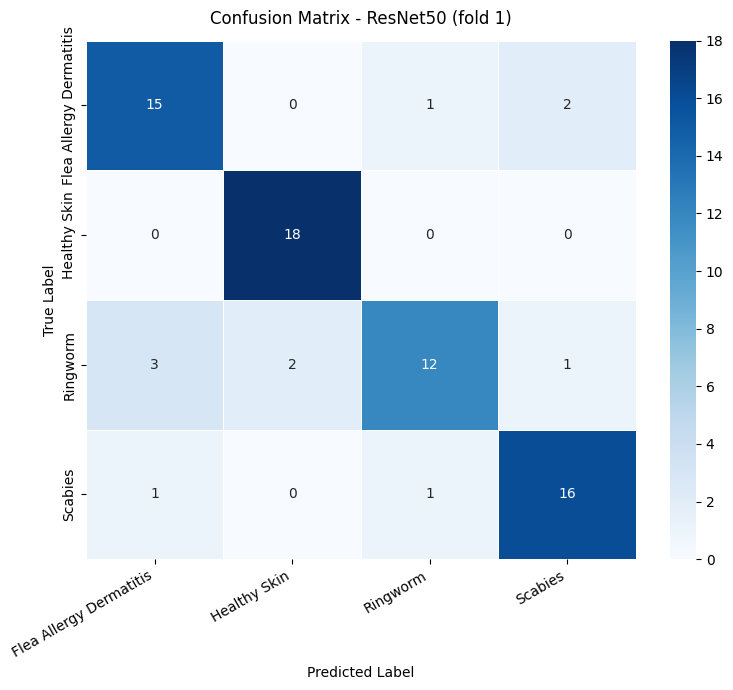

Saved: confusion_matrix_ResNet50.png
Disease-vs-Healthy screening: sens=0.9630 (sick cats caught)  spec=1.0000 (healthy cats cleared)  | missed diseases=2

EfficientNetB0  (representative fold 1)
Accuracy: 0.8472    MCC: 0.8019

                         precision    recall  f1-score   support

Flea Allergy Dermatitis     0.8000    0.8889    0.8421        18
           Healthy Skin     0.7826    1.0000    0.8780        18
               Ringworm     0.8571    0.6667    0.7500        18
                Scabies     1.0000    0.8333    0.9091        18

               accuracy                         0.8472        72
              macro avg     0.8599    0.8472    0.8448        72
           weighted avg     0.8599    0.8472    0.8448        72

Per-class sensitivity / specificity:
  Flea Allergy Dermatitis      sens=0.8889  spec=0.9259
  Healthy Skin                 sens=1.0000  spec=0.9074
  Ringworm                     sens=0.6667  spec=0.9630
  Scabies                      sens=0.8333 

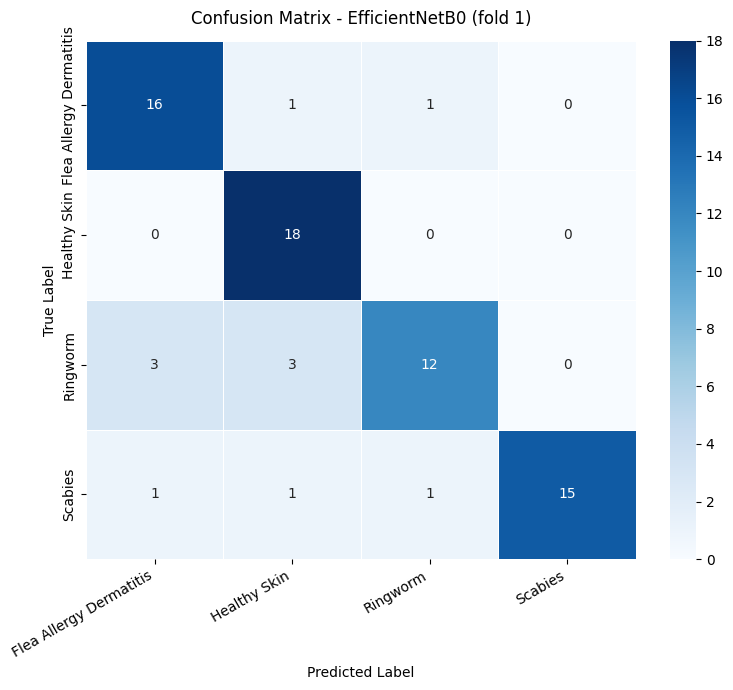

Saved: confusion_matrix_EfficientNetB0.png
Disease-vs-Healthy screening: sens=0.9074 (sick cats caught)  spec=1.0000 (healthy cats cleared)  | missed diseases=5

MobileNetV2  (representative fold 1)
Accuracy: 0.7917    MCC: 0.7235

                         precision    recall  f1-score   support

Flea Allergy Dermatitis     0.7778    0.7778    0.7778        18
           Healthy Skin     0.8095    0.9444    0.8718        18
               Ringworm     0.7059    0.6667    0.6857        18
                Scabies     0.8750    0.7778    0.8235        18

               accuracy                         0.7917        72
              macro avg     0.7920    0.7917    0.7897        72
           weighted avg     0.7920    0.7917    0.7897        72

Per-class sensitivity / specificity:
  Flea Allergy Dermatitis      sens=0.7778  spec=0.9259
  Healthy Skin                 sens=0.9444  spec=0.9259
  Ringworm                     sens=0.6667  spec=0.9074
  Scabies                      sens=0.77

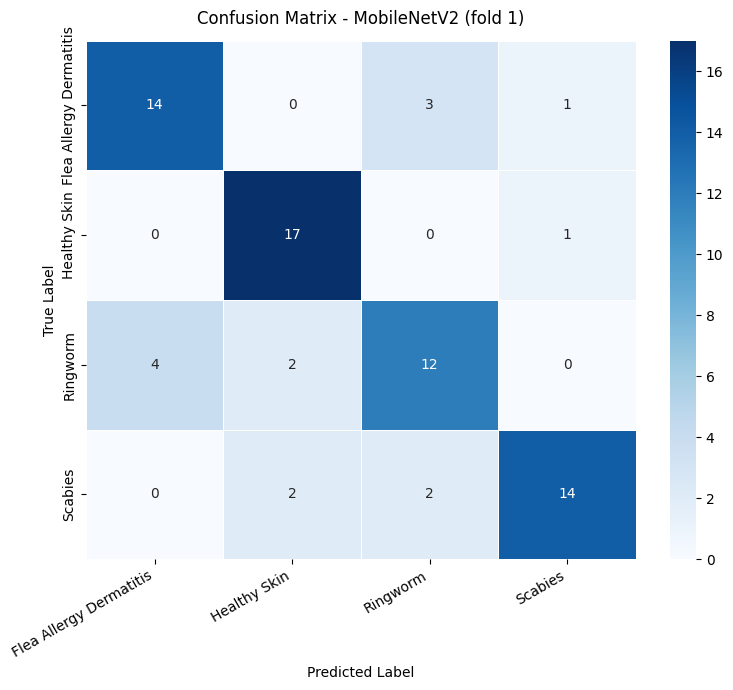

Saved: confusion_matrix_MobileNetV2.png
Disease-vs-Healthy screening: sens=0.9259 (sick cats caught)  spec=0.9444 (healthy cats cleared)  | missed diseases=4


In [ ]:
# ============================================================
# CELL 8: Representative-fold deep dive
# Confusion matrix, classification report, sensitivity & specificity.
# Models reloaded from checkpoints (no retraining).
#
# FIX (v4.1): each model is fed images preprocessed with ITS OWN
# preprocess_input. We load the raw [0,255] fold images ONCE (order
# preserved, shuffle=False), reuse them for every architecture by
# preprocessing a per-arch copy, and keep the raw copy for Grad-CAM
# display in CELL 10. Evaluation here therefore matches CELL 6 exactly.
# ============================================================
def compute_sensitivity_specificity(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    out = {}
    for i, cls in enumerate(labels):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = cm.sum() - TP - FN - FP
        out[cls] = {
            'sensitivity': TP / (TP + FN) if (TP + FN) else 0.0,
            'specificity': TN / (TN + FP) if (TN + FP) else 0.0,
            'TP': int(TP), 'FN': int(FN), 'FP': int(FP), 'TN': int(TN),
        }
    return out

rep_val_df = fold_val_dfs[REP_FOLD]

# Load the held-out fold ONCE as raw [0,255] images (order preserved).
raw_gen = raw_datagen.flow_from_dataframe(
    rep_val_df, x_col='filepath', y_col='label', classes=CLASS_NAMES,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False)
raw_gen.reset()
_imgs, _lbls = [], []
for _ in range(len(raw_gen)):
    bx, by = next(raw_gen)
    _imgs.append(bx); _lbls.append(by)
x_val_raw = np.concatenate(_imgs)                    # [0,255], for display
y_true_all_int = np.argmax(np.concatenate(_lbls), axis=1)

eval_results = {}
rep_models = {}
for arch in ARCH_CONFIG:
    ckpt = os.path.join(CKPT_DIR, f'{arch}_fold{REP_FOLD}.keras')
    model = tf.keras.models.load_model(ckpt)
    rep_models[arch] = model

    # Preprocess the raw images the way THIS architecture expects.
    x_in = PREPROCESS[arch](x_val_raw.copy())
    y_prob = model.predict(x_in, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc = float(np.mean(y_pred == y_true_all_int))
    mcc = float(matthews_corrcoef(y_true_all_int, y_pred))
    ss  = compute_sensitivity_specificity(y_true_all_int, y_pred, CLASS_NAMES)

    print(f'\n{"="*60}\n{arch}  (representative fold {REP_FOLD})\n{"="*60}')
    print(f'Accuracy: {acc:.4f}    MCC: {mcc:.4f}\n')
    print(classification_report(y_true_all_int, y_pred,
                                target_names=CLASS_NAMES, digits=4))
    print('Per-class sensitivity / specificity:')
    for cls, v in ss.items():
        print(f'  {cls:<28} sens={v["sensitivity"]:.4f}  '
              f'spec={v["specificity"]:.4f}')

    cm = confusion_matrix(y_true_all_int, y_pred, labels=range(NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(f'Confusion Matrix - {arch} (fold {REP_FOLD})', pad=12)
    ax.set_ylabel('True Label'); ax.set_xlabel('Predicted Label')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    plt.tight_layout()
    fn = f'confusion_matrix_{arch}.png'
    plt.savefig(fn, dpi=150, bbox_inches='tight'); plt.show()
    print(f'Saved: {fn}')

    # v4.3: screening view -- does the model tell sick from healthy?
    healthy_idx = [i for i, c in enumerate(CLASS_NAMES) if 'health' in c.lower()]
    if healthy_idx:
        h = healthy_idx[0]
        sick_true = y_true_all_int != h
        sick_pred = y_pred != h
        tp = int(np.sum(sick_true & sick_pred));  fn = int(np.sum(sick_true & ~sick_pred))
        tn = int(np.sum(~sick_true & ~sick_pred)); fp = int(np.sum(~sick_true & sick_pred))
        print(f'Disease-vs-Healthy screening: '
              f'sens={tp/(tp+fn) if tp+fn else 0:.4f} (sick cats caught)  '
              f'spec={tn/(tn+fp) if tn+fp else 0:.4f} (healthy cats cleared)  '
              f'| missed diseases={fn}')

    eval_results[arch] = {
        'accuracy': acc, 'mcc': mcc, 'sens_spec': ss,
        'y_true': y_true_all_int.tolist(),
        'y_pred': y_pred.tolist(),
    }


In [ ]:
# ============================================================
# CELL 9: Previous fold-1 exploratory analysis -- McNemar's test (fold 1 only)
# v5: kept for the record ONLY. NOT the final RQ2 result: the final
#     comparison uses all 360 pooled predictions with Holm correction (R6).
# Tests, for each model pair, whether their errors on the SAME
# held-out images differ significantly. H0: equal error rates.
# ============================================================
from itertools import combinations
try:
    from statsmodels.stats.contingency_tables import mcnemar
    HAVE_SM = True
except ImportError:
    HAVE_SM = False
    from scipy.stats import binomtest

archs = list(ARCH_CONFIG.keys())
print('McNemar pairwise comparison (alpha = 0.05):\n')
print(f'{"Model A":<16}{"Model B":<16}{"b":>4}{"c":>4}{"p-value":>11}{"Sig?":>8}')
print('-' * 67)

for a, b in combinations(archs, 2):
    yt = np.array(eval_results[a]['y_true'])
    pa = np.array(eval_results[a]['y_pred'])
    pb = np.array(eval_results[b]['y_pred'])
    a_ok, b_ok = (pa == yt), (pb == yt)
    n01 = int(np.sum(a_ok & ~b_ok))   # A right, B wrong
    n10 = int(np.sum(~a_ok & b_ok))   # A wrong, B right
    table = [[int(np.sum(a_ok & b_ok)), n01],
             [n10, int(np.sum(~a_ok & ~b_ok))]]
    if HAVE_SM:
        p = mcnemar(table, exact=(n01 + n10) < 25, correction=True).pvalue
    else:
        p = (binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
             if (n01 + n10) else 1.0)
    sig = 'YES' if p < 0.05 else 'no'
    print(f'{a:<16}{b:<16}{n01:>4}{n10:>4}{p:>11.4f}{sig:>8}')

print('\nb = A right / B wrong, c = A wrong / B right.')
print('Few or no significant pairs is expected at this dataset size,')
print('and is itself a legitimate, defensible finding.')

McNemar pairwise comparison (alpha = 0.05):

Model A         Model B            b   c    p-value    Sig?
-------------------------------------------------------------------
ResNet50        EfficientNetB0     4   4     1.0000      no
ResNet50        MobileNetV2        7   3     0.3438      no
EfficientNetB0  MobileNetV2        7   3     0.3438      no

b = A right / B wrong, c = A wrong / B right.
Few or no significant pairs is expected at this dataset size,
and is itself a legitimate, defensible finding.


In [ ]:
# ============================================================
# CELL 10: Grad-CAM explainability (representative fold)
# Shows which image regions drive each prediction -- ideally the lesion
# rather than background fur or lighting.
#
# FIX (v4.1): the model is fed images preprocessed with its own
# preprocess_input (x_val_raw -> PREPROCESS[arch]); the ORIGINAL raw
# image is shown underneath the heatmap for interpretation.
# ============================================================
def last_conv_name(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError('No Conv2D layer found.')

def make_gradcam(img_array, model, conv_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.inputs,
        [model.get_layer(conv_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        channel = preds[:, pred_index]
    grads = tape.gradient(channel, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

def show_gradcam(model, arch, raw_imgs, true_ints, n=3):
    conv_name = last_conv_name(model)
    n = min(n, len(raw_imgs))
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        ax = ax.reshape(2, 1)
    for i in range(n):
        disp = (raw_imgs[i].astype(np.float32) / 255.0)          # viewing
        x_in = PREPROCESS[arch](raw_imgs[i:i+1].astype(np.float32).copy())
        hm, pidx = make_gradcam(x_in, model, conv_name)
        hm = tf.image.resize(hm[..., np.newaxis], (224, 224)).numpy().squeeze()
        tidx = int(true_ints[i])
        ax[0, i].imshow(disp); ax[0, i].axis('off')
        ax[0, i].set_title(f'True: {CLASS_NAMES[tidx]}', fontsize=9)
        ax[1, i].imshow(disp); ax[1, i].imshow(hm, cmap='jet', alpha=0.45)
        ax[1, i].axis('off')
        mark = '\u2713' if pidx == tidx else '\u2717'
        ax[1, i].set_title(f'Pred: {CLASS_NAMES[pidx]} {mark}', fontsize=9)
    plt.suptitle(f'Grad-CAM - {arch} (fold {REP_FOLD})', fontsize=13)
    plt.tight_layout()
    fn = f'gradcam_{arch}.png'
    plt.savefig(fn, dpi=150, bbox_inches='tight'); plt.show()
    print(f'Saved: {fn}')

# v4.3: pick one example per class (incl. healthy) instead of the first 3
_pick = [int(np.where(y_true_all_int == k)[0][0])
         for k in range(NUM_CLASSES) if np.any(y_true_all_int == k)]
for arch in ARCH_CONFIG:
    show_gradcam(rep_models[arch], arch, x_val_raw[_pick],
                 y_true_all_int[_pick], n=len(_pick))


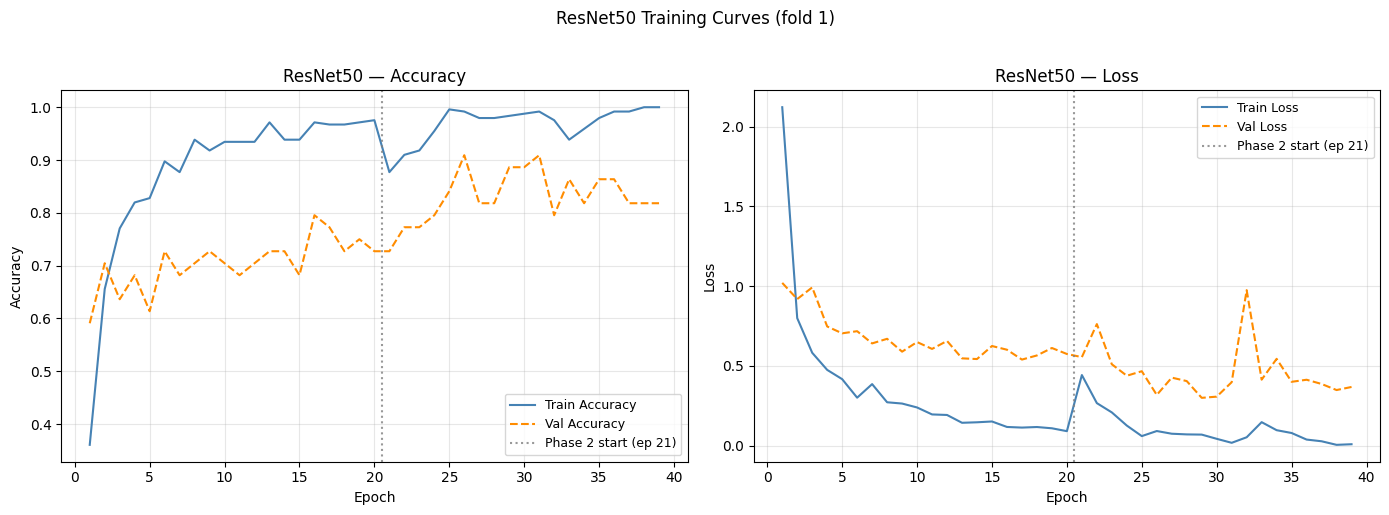

Saved: training_curves_ResNet50.png


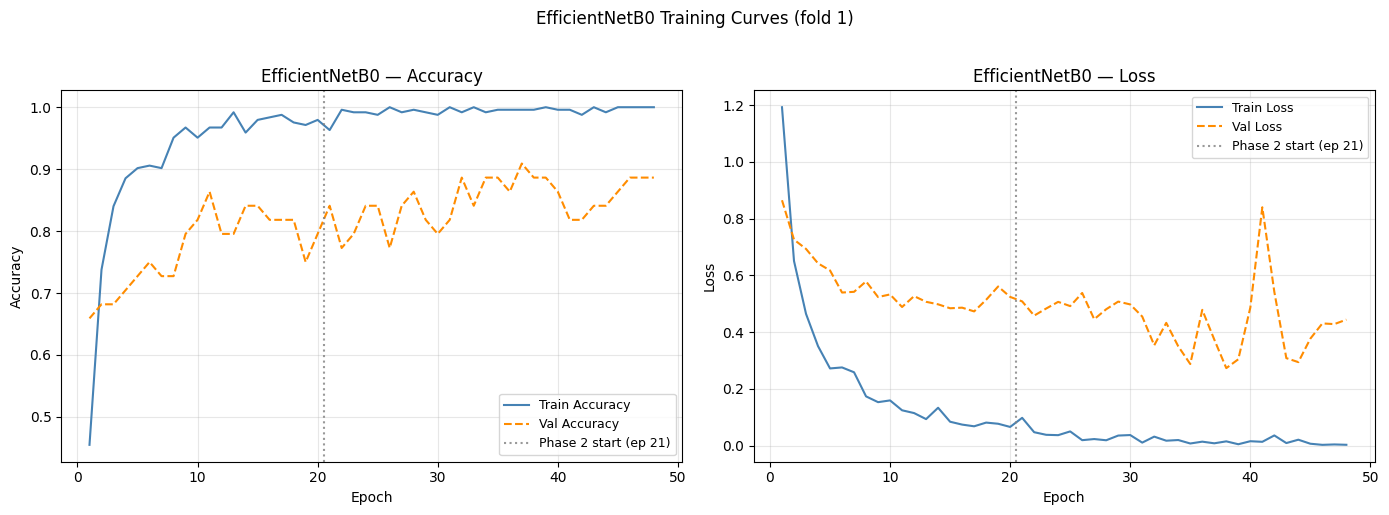

Saved: training_curves_EfficientNetB0.png


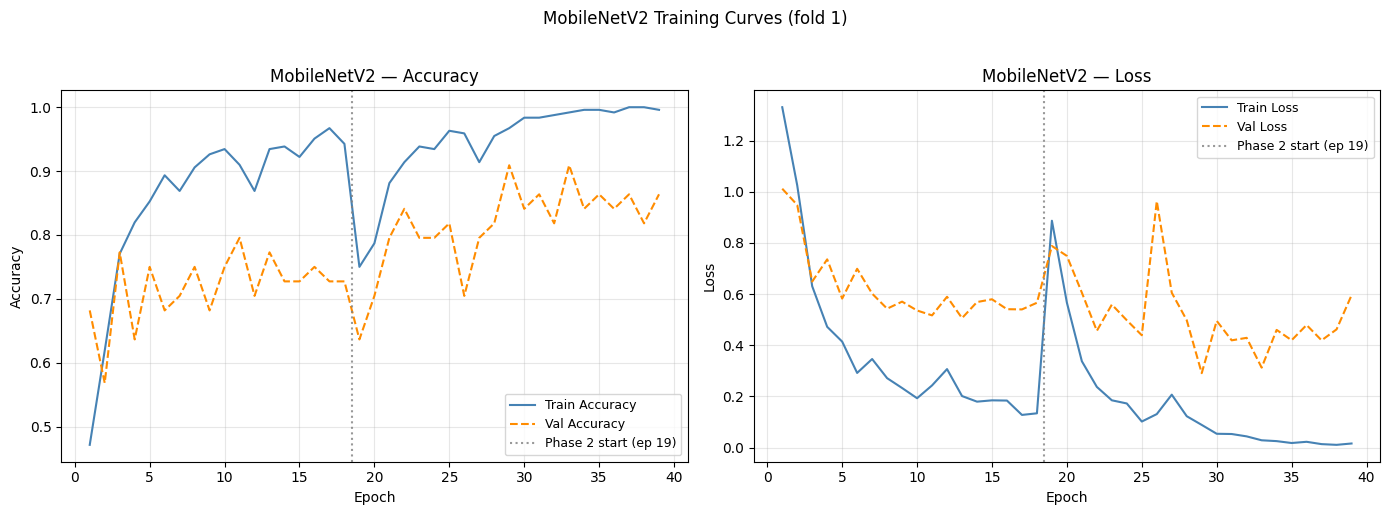

Saved: training_curves_MobileNetV2.png


In [ ]:
# ============================================================
# CELL 11: Training curves (representative fold, Phase 1 + 2)
# ============================================================
def plot_curves(arch):
    h = fold_histories[(arch, REP_FOLD)]
    p1 = fold_phase1_len[(arch, REP_FOLD)]
    n = len(h['accuracy'])
    xs = range(1, n + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for ax, met, lab in [(ax1, 'accuracy', 'Accuracy'),
                         (ax2, 'loss', 'Loss')]:
        ax.plot(xs, h[met], label=f'Train {lab}',
                color='steelblue', linewidth=1.5)
        ax.plot(xs, h['val_' + met], '--', label=f'Val {lab}',
                color='darkorange', linewidth=1.5)
        ax.axvline(x=p1 + 0.5, color='gray', linestyle=':', alpha=0.8,
                   label=f'Phase 2 start (ep {p1+1})')
        ax.set_title(f'{arch} — {lab}'); ax.set_xlabel('Epoch')
        ax.set_ylabel(lab); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.suptitle(f'{arch} Training Curves (fold {REP_FOLD})', y=1.02)
    plt.tight_layout()
    fn = f'training_curves_{arch}.png'
    plt.savefig(fn, dpi=150, bbox_inches='tight'); plt.show()
    print(f'Saved: {fn}')

for arch in ARCH_CONFIG:
    plot_curves(arch)

In [ ]:
# ============================================================
# CELL 12: Computational efficiency
# Total params, model size (MB), inference time (ms). The timing
# loop forces a sync so GPU kernels finish before the timer stops.
# ============================================================
efficiency_results = {}

def compute_efficiency(model, arch):
    total = model.count_params()
    trainable = int(sum(tf.size(w).numpy() for w in model.trainable_weights))

    p = f'/content/{arch}_size_check.keras'
    model.save(p)
    size_mb = os.path.getsize(p) / (1024 * 1024)
    os.remove(p)

    dummy = np.random.rand(1, 224, 224, 3).astype(np.float32)
    for _ in range(5):                       # warmup + sync
        _ = float(tf.reduce_sum(model(dummy, training=False)))
    times = []
    for _ in range(50):
        t0 = time.perf_counter()
        out = model(dummy, training=False)
        _ = float(tf.reduce_sum(out))        # force kernels to finish
        times.append((time.perf_counter() - t0) * 1000)

    efficiency_results[arch] = {
        'total_params': int(total),
        'trainable_params': trainable,
        'size_mb': float(size_mb),
        'inference_ms': float(np.mean(times)),
        'inference_std': float(np.std(times)),
    }
    print(f'{arch:<16} params={total:>12,}  size={size_mb:>6.1f}MB  '
          f'inf={np.mean(times):>6.2f} ± {np.std(times):.2f} ms')

for arch in ARCH_CONFIG:
    compute_efficiency(rep_models[arch], arch)

ResNet50         params=  24,113,284  size= 227.7MB  inf=271.20 ± 41.53 ms
EfficientNetB0   params=   4,378,535  size=  43.3MB  inf=404.64 ± 258.61 ms
MobileNetV2      params=   2,586,948  size=  26.1MB  inf=169.29 ± 8.02 ms


In [ ]:
# ============================================================
# CELL 13: FLOPs (representative-fold models)
# ============================================================
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)
from tensorflow.python.framework.convert_to_constants import (
    convert_variables_to_constants_v2)

def get_flops(model, arch):
    @tf.function
    def forward(x):
        return model(x, training=False)
    concrete = forward.get_concrete_function(
        tf.TensorSpec((1, 224, 224, 3), tf.float32))
    frozen = convert_variables_to_constants_v2(concrete)
    graph_def = frozen.graph.as_graph_def()
    with tf.Graph().as_default() as g:
        tf.graph_util.import_graph_def(graph_def, name='')
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(
            g, run_meta=tf.compat.v1.RunMetadata(), cmd='op', options=opts)
    gflops = flops.total_float_ops / 1e9
    efficiency_results[arch]['flops'] = int(flops.total_float_ops)
    efficiency_results[arch]['gflops'] = float(gflops)
    print(f'{arch:<16} {flops.total_float_ops:>15,}  ({gflops:.2f} GFLOPs)')

for arch in ARCH_CONFIG:
    get_flops(rep_models[arch], arch)

ResNet50           7,752,248,216  (7.75 GFLOPs)
EfficientNetB0       801,442,863  (0.80 GFLOPs)
MobileNetV2          613,383,896  (0.61 GFLOPs)


In [ ]:
# ============================================================
# CELL 14: Legacy v4.3 summary (kept unchanged for comparison)
# v5: superseded by 'FINAL MANUSCRIPT RESULTS' at the end of the notebook.
#     This cell has no ranking, composite score or winner selection.
# Accuracy/MCC/F1 are CV mean ± std; efficiency is per-architecture.
# ============================================================
archs = list(ARCH_CONFIG.keys())
print('=' * 80)
print('FINAL COMPARATIVE SUMMARY')
print('=' * 80)
print(f'{"Metric":<26}' + ''.join(f'{a:>18}' for a in archs))
print('-' * 80)

def row(label, vals):
    print(f'{label:<26}' + ''.join(f'{v:>18}' for v in vals))

row('CV Accuracy (%)',
    [f'{cv_summary[a]["acc_mean"]*100:.2f}±{cv_summary[a]["acc_std"]*100:.2f}'
     for a in archs])
row('CV MCC',
    [f'{cv_summary[a]["mcc_mean"]:.3f}±{cv_summary[a]["mcc_std"]:.3f}'
     for a in archs])
row('CV Macro-F1',
    [f'{cv_summary[a]["f1_mean"]:.3f}±{cv_summary[a]["f1_std"]:.3f}'
     for a in archs])
row('Total Parameters',
    [f'{efficiency_results[a]["total_params"]:,}' for a in archs])
row('Model Size (MB)',
    [f'{efficiency_results[a]["size_mb"]:.1f}' for a in archs])
row('FLOPs (GFLOPs)',
    [f'{efficiency_results[a].get("gflops", 0):.2f}' for a in archs])
row('Avg Inference (ms)',
    [f'{efficiency_results[a]["inference_ms"]:.2f}' for a in archs])
print('=' * 80)
print(f'\nAll accuracy/MCC/F1 values are {N_SPLITS}-fold CV mean ± std.')
print(f'Confusion matrices, sensitivity/specificity and Grad-CAM are from '
      f'representative fold {REP_FOLD}.')

FINAL COMPARATIVE SUMMARY
Metric                              ResNet50    EfficientNetB0       MobileNetV2
--------------------------------------------------------------------------------
CV Accuracy (%)                   86.11±4.12        84.72±3.83        81.67±5.08
CV MCC                           0.820±0.053       0.801±0.049       0.761±0.067
CV Macro-F1                      0.858±0.044       0.846±0.039       0.815±0.052
Total Parameters                  24,113,284         4,378,535         2,586,948
Model Size (MB)                        227.7              43.3              26.1
FLOPs (GFLOPs)                          7.75              0.80              0.61
Avg Inference (ms)                    271.20            404.64            169.29

All accuracy/MCC/F1 values are 5-fold CV mean ± std.
Confusion matrices, sensitivity/specificity and Grad-CAM are from representative fold 1.


In [ ]:
# ============================================================
# CELL 15: Persist all results to disk (survives disconnects)
# ============================================================
def to_serialisable(obj):
    if isinstance(obj, dict):
        return {k: to_serialisable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_serialisable(v) for v in obj]
    if isinstance(obj, np.integer):  return int(obj)
    if isinstance(obj, np.floating): return float(obj)
    if isinstance(obj, np.ndarray):  return obj.tolist()
    return obj

with open('cv_summary.json', 'w') as f:
    json.dump(to_serialisable(cv_summary), f, indent=2)
with open('cv_metrics_per_fold.json', 'w') as f:
    json.dump(to_serialisable(cv_metrics), f, indent=2)
with open('eval_results_repfold.json', 'w') as f:
    json.dump(to_serialisable(eval_results), f, indent=2)
with open('efficiency_results.json', 'w') as f:
    json.dump(to_serialisable(efficiency_results), f, indent=2)

with open('summary_table.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['Model', 'CV_Acc_mean(%)', 'CV_Acc_std', 'CV_MCC_mean',
                'CV_MCC_std', 'CV_F1_mean', 'CV_F1_std', 'TotalParams',
                'SizeMB', 'GFLOPs', 'InferenceMs', 'RepFold'])
    for a in ARCH_CONFIG:
        c, e = cv_summary[a], efficiency_results[a]
        w.writerow([a,
                    round(c['acc_mean']*100, 2), round(c['acc_std']*100, 2),
                    round(c['mcc_mean'], 4), round(c['mcc_std'], 4),
                    round(c['f1_mean'], 4), round(c['f1_std'], 4),
                    e['total_params'], round(e['size_mb'], 2),
                    round(e.get('gflops', 0), 2), round(e['inference_ms'], 2),
                    REP_FOLD])

print('Saved: cv_summary.json, cv_metrics_per_fold.json,')
print('       eval_results_repfold.json, efficiency_results.json,')
print('       summary_table.csv  (+ PNGs from earlier cells)')

# Optional: back up to Drive so a disconnect can't lose your run.
# Uncomment the three lines below.
# OUT = '/content/drive/MyDrive/cat_skin_results'; os.makedirs(OUT, exist_ok=True)
# for fn in os.listdir('.'):
#     if fn.endswith(('.json', '.csv', '.png')): shutil.copy2(fn, OUT)

Saved: cv_summary.json, cv_metrics_per_fold.json,
       eval_results_repfold.json, efficiency_results.json,
       summary_table.csv  (+ PNGs from earlier cells)


# v5 REVISION ANALYSES (RQ1-RQ3)

**What this section produces**

| Cell | Purpose | RQ / RO |
|---|---|---|
| R1 | Reporting conventions (class order FAD → Ringworm → Scabies → Healthy skin; model order ResNet50 → MobileNetV2 → EfficientNetB0), α = .05, Holm, bootstrap settings, metric helpers | all |
| R2 | Collects the out-of-fold predictions for **all 5 folds × 3 models** and checks them against the original v4.3 printout | RO1, RO2 |
| R3 | Pooled 360-row prediction table + alignment checks → `final_predictions.csv` | RO2 |
| R4 | Accuracy, macro-F1, MCC (pooled and per fold), per-class P/R/F1/support, confusion matrices, independent verification | RO1 |
| R5 | Disease-vs-healthy screening (pooled and per fold) | RO1 |
| R6 | Pairwise McNemar on the pooled 360 predictions + Holm correction | RO2 |
| R7 | Bootstrap 95% CIs for accuracy, macro-F1 **and MCC** (verifies CELL 7b) | RO1 |
| R8 | Total / trainable / non-trainable parameters for Phase 1 **and** Phase 2 | RO1 |
| R9 | FLOPs (same method as CELL 13) + ratios from unrounded values | RO1 |
| R10 | Model file size, same `.keras` format: (A) CELL 12 method, (B) inference-only | RO1 |
| R11 | Inference time with the CELL 12 protocol (+ separate graph-mode supplement) | RO1 |
| R12–R14 | Clean tables, FINAL MANUSCRIPT RESULTS, reproducibility, provenance, consistency check | RQ1–RQ3 |

**How to run**

* **v4.3 runtime still alive** (CELL 6 variables in memory): run R1 → R14 directly. R2 uses the in-memory predictions.
* **v5 backup exists on Drive** (`cat_skin_results_v5/ckpts`): run CELLs 1–5, **skip CELL 6**, then run R1 → R14. R2 re-evaluates the saved checkpoints; nothing is retrained.
* **Neither** (the v4.3 models lived only in `/content` and are gone once the runtime ends): *Runtime → Disconnect and delete runtime*, then **Run all**. CELL 6 retrains with the unchanged protocol (~70 min on a T4). R2 then reports whether every per-fold value reproduces v4.3 exactly. If it does not, use the new run for **all** manuscript numbers.

All v5 outputs go to `MyDrive/cat_skin_results_v5/` (a new folder; nothing from v4.3 is overwritten).


In [ ]:
# ============================================================
# R1 (v5): Revision-analysis configuration, reference values, helpers
#
# Nothing here changes the experiment. It only fixes HOW results are
# reported: class order, model order, alpha, correction, bootstrap.
# REF_V43 holds the numbers printed by the original v4.3 run (CELL 6/7b/
# 12/13 outputs). They are used ONLY to check whether the predictions
# analysed below are the original ones or a re-run.
# ============================================================
import os, sys, json, platform, subprocess, itertools
import numpy as np, pandas as pd
from sklearn.metrics import (confusion_matrix, matthews_corrcoef, f1_score,
                             precision_recall_fscore_support, accuracy_score)
from scipy.stats import binomtest, chi2

# ---- output folder: NEW folder, never overwrites v4.3 files ----
V5_OUT_DIR = globals().get('V5_OUT_DIR', '/content/drive/MyDrive/cat_skin_results_v5')
os.makedirs(V5_OUT_DIR, exist_ok=True)
CKPT_DIR = globals().get('CKPT_DIR', '/content/ckpts')
def out(fn): return os.path.join(V5_OUT_DIR, fn)

# ---- reporting conventions ----
MODELS = ['ResNet50', 'MobileNetV2', 'EfficientNetB0']        # display order
def _find(word):
    hits = [i for i, c in enumerate(CLASS_NAMES) if word in c.lower()]
    assert len(hits) == 1, f'could not identify class containing "{word}" in {CLASS_NAMES}'
    return hits[0]
# Model label integers are alphabetical (CLASS_NAMES); DISPLAY_ORDER maps them
# to the manuscript order without touching the models.
DISPLAY_ORDER = [_find('flea'), _find('ringworm'), _find('scabies'), _find('health')]
DISPLAY_NAMES = ['Flea allergy dermatitis', 'Ringworm', 'Scabies', 'Healthy skin']
HEALTHY_INT   = _find('health')
DISEASE_INTS  = [i for i in DISPLAY_ORDER if i != HEALTHY_INT]

ALPHA        = 0.05
CORRECTION   = 'Holm (step-down), 3 pairwise comparisons'
B_BOOT       = 2000          # same as CELL 7b
BOOT_SEED    = SEED          # same as CELL 7b (42)
MCNEMAR_RULE = 'exact binomial if n01+n10 < 25, else chi-square with continuity correction (same rule as CELL 9)'

# ---- values printed by the ORIGINAL v4.3 run (for verification only) ----
REF_V43 = {
    'per_fold': {   # CELL 6 printout, 4 d.p.
        'ResNet50':       dict(accuracy=[.8472,.8750,.9306,.8056,.8472], mcc=[.7986,.8458,.9081,.7509,.7975], macro_f1=[.8433,.8728,.9305,.7964,.8465]),
        'MobileNetV2':    dict(accuracy=[.7917,.8056,.9028,.8333,.7500], mcc=[.7235,.7467,.8722,.7882,.6724], macro_f1=[.7897,.8121,.9017,.8269,.7440]),
        'EfficientNetB0': dict(accuracy=[.8472,.8056,.9167,.8472,.8194], mcc=[.8019,.7522,.8905,.7994,.7600], macro_f1=[.8448,.8024,.9152,.8499,.8167]),
    },
    'bootstrap': {  # CELL 7b printout: acc % (1 d.p.), F1 (3 d.p.)
        'ResNet50':       dict(acc=86.11, acc_ci=[82.5, 89.7], f1=0.862, f1_ci=[0.826, 0.898]),
        'EfficientNetB0': dict(acc=84.72, acc_ci=[81.1, 88.3], f1=0.848, f1_ci=[0.810, 0.883]),
        'MobileNetV2':    dict(acc=81.67, acc_ci=[77.5, 85.6], f1=0.817, f1_ci=[0.774, 0.856]),
    },
    'total_params': {'ResNet50': 24113284, 'EfficientNetB0': 4378535, 'MobileNetV2': 2586948},
    'flops':        {'ResNet50': 7752248216, 'EfficientNetB0': 801442863, 'MobileNetV2': 613383896},
    'size_mb':      {'ResNet50': 227.7, 'EfficientNetB0': 43.3, 'MobileNetV2': 26.1},   # MiB, .keras incl. optimizer state
    'inference_ms': {'ResNet50': (270.85, 51.83), 'EfficientNetB0': (350.71, 53.47), 'MobileNetV2': (171.37, 24.82)},
    'fold1_mcnemar': {('ResNet50','EfficientNetB0'): (4, 4, 1.0000), ('ResNet50','MobileNetV2'): (7, 3, 0.3438),
                      ('EfficientNetB0','MobileNetV2'): (7, 3, 0.3438)},
}

PROVENANCE = []   # (result, category, note) -- filled as cells run
def log_prov(result, category, note=''):
    PROVENANCE.append(dict(result=result, category=category, note=note))

# ---- metric helpers (written out explicitly so they can be checked) ----
def cm_display(y_true, y_pred):
    """Confusion matrix in manuscript order (rows = true, cols = predicted)."""
    return confusion_matrix(y_true, y_pred, labels=DISPLAY_ORDER)

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=DISPLAY_ORDER, zero_division=0)
    cm = cm_display(y_true, y_pred); n = cm.sum()
    spec = [(n - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]) / (n - cm[i, :].sum()) for i in range(len(DISPLAY_ORDER))]
    return pd.DataFrame({'class': DISPLAY_NAMES, 'precision': p, 'recall': r, 'f1': f,
                         'specificity': spec, 'support': s})

def overall(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, labels=DISPLAY_ORDER, average='macro', zero_division=0),
                mcc=matthews_corrcoef(y_true, y_pred))

def screening(y_true, y_pred):
    """Disease = positive. FAD/Ringworm/Scabies -> disease; Healthy skin -> healthy.
    A disease image predicted as a DIFFERENT disease still counts as a correct
    'disease' call (TP) in this binary view."""
    yt = np.asarray(y_true) != HEALTHY_INT
    yp = np.asarray(y_pred) != HEALTHY_INT
    TP = int(np.sum(yt & yp));  FN = int(np.sum(yt & ~yp))
    TN = int(np.sum(~yt & ~yp)); FP = int(np.sum(~yt & yp))
    d = lambda a, b: a / b if b else float('nan')
    sens = d(TP, TP + FN); prec = d(TP, TP + FP)
    return dict(TP=TP, FN=FN, TN=TN, FP=FP,
                sensitivity=sens, recall=sens, specificity=d(TN, TN + FP),
                precision=prec, npv=d(TN, TN + FN),
                f1=d(2 * TP, 2 * TP + FP + FN), accuracy=d(TP + TN, TP + TN + FP + FN),
                diseased_called_healthy=FN, healthy_called_diseased=FP)

def mcc_from_cm(cm):
    """Multiclass MCC (Gorodkin) computed by hand from the confusion matrix."""
    cm = np.asarray(cm, dtype=float); n = cm.sum(); c = np.trace(cm)
    t = cm.sum(1); p = cm.sum(0)
    den = np.sqrt((n**2 - (p**2).sum()) * (n**2 - (t**2).sum()))
    return (c * n - (t * p).sum()) / den if den else 0.0

def mcnemar_counts(yt, pa, pb):
    a_ok = np.asarray(pa) == np.asarray(yt); b_ok = np.asarray(pb) == np.asarray(yt)
    return dict(n00=int(np.sum(a_ok & b_ok)),    # A correct, B correct
                n01=int(np.sum(a_ok & ~b_ok)),   # A correct, B incorrect
                n10=int(np.sum(~a_ok & b_ok)),   # A incorrect, B correct
                n11=int(np.sum(~a_ok & ~b_ok)))  # A incorrect, B incorrect

def mcnemar_test(n01, n10):
    """Same decision rule as CELL 9. Returns (variant, statistic, p)."""
    n = n01 + n10
    if n == 0:
        return 'no discordant pairs', float('nan'), 1.0
    if n < 25:
        return 'exact binomial (two-sided)', float(min(n01, n10)), float(binomtest(min(n01, n10), n, 0.5).pvalue)
    stat = (abs(n01 - n10) - 1) ** 2 / n
    return 'chi-square, continuity-corrected (df=1)', float(stat), float(chi2.sf(stat, 1))

def fmt_p(p):
    return '< .0001' if p < 1e-4 else f'{p:.4f}'

def holm(pvals):
    """Holm step-down adjusted p-values, in the original order."""
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj

print('Output folder :', V5_OUT_DIR)
print('Class order   :', [CLASS_NAMES[i] for i in DISPLAY_ORDER], '->', DISPLAY_NAMES)
print('Model order   :', MODELS)
print(f'alpha={ALPHA} | correction={CORRECTION} | bootstrap B={B_BOOT}, seed={BOOT_SEED}')


Output folder : /content/drive/MyDrive/cat_skin_results_v5
Class order   : ['Flea Allergy Dermatitis', 'Ringworm', 'Scabies', 'Healthy Skin'] -> ['Flea allergy dermatitis', 'Ringworm', 'Scabies', 'Healthy skin']
Model order   : ['ResNet50', 'MobileNetV2', 'EfficientNetB0']
alpha=0.05 | correction=Holm (step-down), 3 pairwise comparisons | bootstrap B=2000, seed=42


In [ ]:
# ============================================================
# R2 (v5): Obtain out-of-fold predictions for ALL 5 folds x 3 models
#
# Source priority (first one available is used, and is recorded):
#   A. fold_pred_records from CELL 6 in THIS session (v5 CELL 6 keeps
#      file paths + probabilities for every test image).
#   B. fold_predictions + fold_val_dfs from CELL 6 in this session
#      (e.g. a still-alive v4.3 runtime): labels/preds only.
#   C. Saved checkpoints (/content/ckpts or the v5 Drive backup): the
#      folds are re-created with the SAME StratifiedKFold(seed=42) call
#      as CELL 6 and every checkpoint is re-evaluated exactly as CELL 6
#      does (shuffle=False, per-architecture preprocess_input).
#   D. None of the above -> [BLOCKED]; run CELLs 1-6 first.
# The models are never retrained here.
# ============================================================
import glob
from sklearn.model_selection import StratifiedKFold

ARCHS = list(ARCH_CONFIG.keys())
_expected = {(a, f) for a in ARCHS for f in range(1, N_SPLITS + 1)}
PRED_SOURCE = None
records = {}

def _rec_df(arch, fold, filepaths, y_true, y_pred, y_prob=None):
    df = pd.DataFrame({'arch': arch, 'fold': fold, 'pos_in_fold': np.arange(len(filepaths)),
                       'filepath': list(filepaths),
                       'y_true': np.asarray(y_true, int), 'y_pred': np.asarray(y_pred, int)})
    if y_prob is not None:
        for k, c in enumerate(CLASS_NAMES):
            df[f'prob_{c}'] = np.asarray(y_prob)[:, k]
    return df

if 'fold_pred_records' in globals() and set(fold_pred_records) >= _expected:
    PRED_SOURCE = 'A: CELL 6 of this session (v5 records with file paths + probabilities)'
    records = {k: fold_pred_records[k] for k in _expected}

elif ('fold_predictions' in globals() and set(fold_predictions) >= _expected
      and 'fold_val_dfs' in globals() and len(fold_val_dfs) >= N_SPLITS):
    PRED_SOURCE = 'B: fold_predictions + fold_val_dfs from CELL 6 of this session'
    for (a, f) in sorted(_expected):
        yt, yp = fold_predictions[(a, f)]
        tdf = fold_val_dfs[f]
        exp_true = tdf['label'].map({c: i for i, c in enumerate(CLASS_NAMES)}).values
        assert np.array_equal(np.asarray(yt), exp_true), f'label/order mismatch {a} fold {f}'
        records[(a, f)] = _rec_df(a, f, tdf['filepath'].values, yt, yp)

else:
    cand_dirs = [CKPT_DIR, os.path.join(V5_OUT_DIR, 'ckpts')]
    ckpt_dir = next((d for d in cand_dirs
                     if all(os.path.exists(os.path.join(d, f'{a}_fold{f}.keras')) for a, f in _expected)), None)
    if ckpt_dir is None:
        raise RuntimeError(
            '[BLOCKED] No out-of-fold predictions and no complete set of 15 checkpoints found in '
            f'{cand_dirs}.\nThe pooled 360-image analysis (RQ1 per-class/screening, RQ2 McNemar, '
            'bootstrap) cannot be produced without them.\nMinimum fix: start a FRESH runtime and run '
            'CELLs 1-6 (training, ~70 min on a T4), then continue from R1.')
    PRED_SOURCE = f'C: re-evaluated saved checkpoints in {ckpt_dir} (no retraining)'
    # Re-create the outer folds exactly as CELL 6 (same data_df, same call).
    _skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    _test_dfs = {f: data_df.iloc[te].reset_index(drop=True)
                 for f, (_, te) in enumerate(_skf.split(data_df['filepath'].values,
                                                        data_df['label'].values), start=1)}
    for (a, f) in sorted(_expected, key=lambda t: (t[1], ARCHS.index(t[0]))):
        tdf = _test_dfs[f]
        gen = make_eval_datagen(a).flow_from_dataframe(
            tdf, x_col='filepath', y_col='label', classes=CLASS_NAMES,
            target_size=IMG_SIZE, batch_size=BATCH_SIZE,
            class_mode='categorical', shuffle=False)
        assert list(gen.filepaths) == list(tdf['filepath']), 'generator order != fold order'
        m = tf.keras.models.load_model(os.path.join(ckpt_dir, f'{a}_fold{f}.keras'))
        prob = m.predict(gen, verbose=0)
        records[(a, f)] = _rec_df(a, f, tdf['filepath'].values, gen.classes, prob.argmax(1), prob)
        del m; tf.keras.backend.clear_session(); gc.collect()
        print(f'  re-evaluated {a} fold {f}')

print('Prediction source:', PRED_SOURCE)

# ---- per-fold metrics + check against the ORIGINAL v4.3 printout ----
rows, mism = [], []
for a in MODELS:
    for f in range(1, N_SPLITS + 1):
        d = records[(a, f)]
        o = overall(d['y_true'], d['y_pred'])
        rows.append(dict(model=a, fold=f, n=len(d), correct=int((d.y_true == d.y_pred).sum()), **o))
        for k in ('accuracy', 'mcc', 'macro_f1'):
            ref = REF_V43['per_fold'][a][k][f - 1]
            if abs(round(o[k], 4) - ref) > 1e-9:
                mism.append(f'{a} fold {f} {k}: now {o[k]:.4f} vs v4.3 {ref:.4f}')
per_fold_df = pd.DataFrame(rows)
MATCHES_V43 = len(mism) == 0
if MATCHES_V43:
    print('\nVERIFIED: all 45 per-fold values (3 models x 5 folds x acc/MCC/macro-F1) equal the '
          'original v4.3 printout to 4 d.p. -> these predictions reproduce the original experiment.')
    log_prov('Out-of-fold predictions (all 5 folds)', 'reused/reproduced',
             PRED_SOURCE + '; all 45 per-fold values identical to v4.3 printout')
else:
    print(f'\nWARNING: {len(mism)} per-fold values differ from the original v4.3 printout:')
    for m_ in mism: print('   ', m_)
    print('These predictions come from a RE-RUN that did not reproduce v4.3 bit-for-bit.\n'
          'Use THIS run for ALL manuscript numbers (do not mix runs) -- see the consistency check.')
    log_prov('Out-of-fold predictions (all 5 folds)', 'newly generated (re-run)',
             PRED_SOURCE + f'; {len(mism)} per-fold values differ from v4.3')


Prediction source: A: CELL 6 of this session (v5 records with file paths + probabilities)

VERIFIED: all 45 per-fold values (3 models x 5 folds x acc/MCC/macro-F1) equal the original v4.3 printout to 4 d.p. -> these predictions reproduce the original experiment.


In [ ]:
# ============================================================
# R3 (v5): Pooled prediction table (360 rows) + alignment checks
#
# sample_id = the image's path inside the letterboxed pool
#             ("<class folder>/<original file stem>.png", CELL 2).
#             This is the identifier the notebook already uses; no new IDs.
# ============================================================
POOL_ROOT = globals().get('RAW_POOL', '/content/raw_pool')
long_df = pd.concat([records[k] for k in sorted(records)], ignore_index=True)
long_df['sample_id'] = long_df['filepath'].map(lambda p: os.path.relpath(p, POOL_ROOT))

# ---------------- alignment checks ----------------
checks = []
def check(name, ok, detail=''):
    checks.append(dict(check=name, passed=bool(ok), detail=detail))
    print(('PASS  ' if ok else 'FAIL  ') + name + (f'  ({detail})' if detail else ''))

ids = {a: long_df[long_df.arch == a].sort_values(['fold', 'pos_in_fold'])['sample_id'].tolist() for a in MODELS}
N_EXPECTED = len(data_df)   # 360 in this study
check(f'each model has {N_EXPECTED} predictions (one per dataset image)', all(len(v) == N_EXPECTED for v in ids.values()),
      ', '.join(f'{a}={len(v)}' for a, v in ids.items()))
check('no image predicted twice within a model', all(len(set(v)) == len(v) for v in ids.values()))
check('identical sample set across models', len({frozenset(v) for v in ids.values()}) == 1)
check('identical sample ORDER across models', all(ids[a] == ids[MODELS[0]] for a in MODELS))
check('every dataset image is tested exactly once',
      set(ids[MODELS[0]]) == set(data_df['filepath'].map(lambda p: os.path.relpath(p, POOL_ROOT))))

wide = long_df.pivot(index='sample_id', columns='arch', values='y_pred')
yt_w = long_df.pivot(index='sample_id', columns='arch', values='y_true')
fd_w = long_df.pivot(index='sample_id', columns='arch', values='fold')
check('true labels identical across models', (yt_w.nunique(axis=1) == 1).all())
check('fold assignment identical across models', (fd_w.nunique(axis=1) == 1).all())
check('no missing predictions', not wide.isna().any().any())
lab_from_path = long_df['filepath'].map(lambda p: CLASS_NAMES.index(os.path.basename(os.path.dirname(p))))
check('true label agrees with class folder of every file', (lab_from_path == long_df['y_true']).all())

final_pred = pd.DataFrame({
    'sample_id': wide.index,
    'fold': fd_w[MODELS[0]].astype(int).values,
    'true_label': [CLASS_NAMES[i] for i in yt_w[MODELS[0]].astype(int)],
})
for a in MODELS:
    final_pred[a] = [CLASS_NAMES[i] for i in wide[a].astype(int)]
final_pred = final_pred.sort_values(['fold', 'sample_id']).reset_index(drop=True)
final_pred.to_csv(out('final_predictions.csv'), index=False)
long_df.to_csv(out('final_predictions_long_with_probabilities.csv'), index=False)

# pooled vectors used by every later cell (same order for all models)
order_df = long_df[long_df.arch == MODELS[0]].sort_values(['fold', 'pos_in_fold'])
Y_TRUE = order_df['y_true'].to_numpy()
Y_PRED = {a: long_df[long_df.arch == a].sort_values(['fold', 'pos_in_fold'])['y_pred'].to_numpy() for a in MODELS}

print(f'\nObservations: {len(Y_TRUE)}')
print('Per class   :', {DISPLAY_NAMES[k]: int(np.sum(Y_TRUE == i)) for k, i in enumerate(DISPLAY_ORDER)})
print('Per fold    :', final_pred['fold'].value_counts().sort_index().to_dict())
for a in MODELS:
    c = int(np.sum(Y_PRED[a] == Y_TRUE))
    print(f'Correct     : {a:<15} {c}/{len(Y_TRUE)}  (independent accuracy = {c/len(Y_TRUE):.6f})')
pd.DataFrame(checks).to_csv(out('validation_alignment_checks.csv'), index=False)
assert all(c['passed'] for c in checks), 'Alignment check failed -- do NOT use the pooled analysis until fixed.'
log_prov('Pooled 360-prediction table (final_predictions.csv)', 'recalculated from predictions')
print('\nSaved: final_predictions.csv, final_predictions_long_with_probabilities.csv')


PASS  each model has 360 predictions (one per dataset image)  (ResNet50=360, MobileNetV2=360, EfficientNetB0=360)
PASS  no image predicted twice within a model
PASS  identical sample set across models
PASS  identical sample ORDER across models
PASS  every dataset image is tested exactly once
PASS  true labels identical across models
PASS  fold assignment identical across models
PASS  no missing predictions
PASS  true label agrees with class folder of every file

Observations: 360
Per class   : {'Flea allergy dermatitis': 90, 'Ringworm': 90, 'Scabies': 90, 'Healthy skin': 90}
Per fold    : {1: 72, 2: 72, 3: 72, 4: 72, 5: 72}
Correct     : ResNet50        310/360  (independent accuracy = 0.861111)
Correct     : MobileNetV2     294/360  (independent accuracy = 0.816667)
Correct     : EfficientNetB0  305/360  (independent accuracy = 0.847222)

Saved: final_predictions.csv, final_predictions_long_with_probabilities.csv


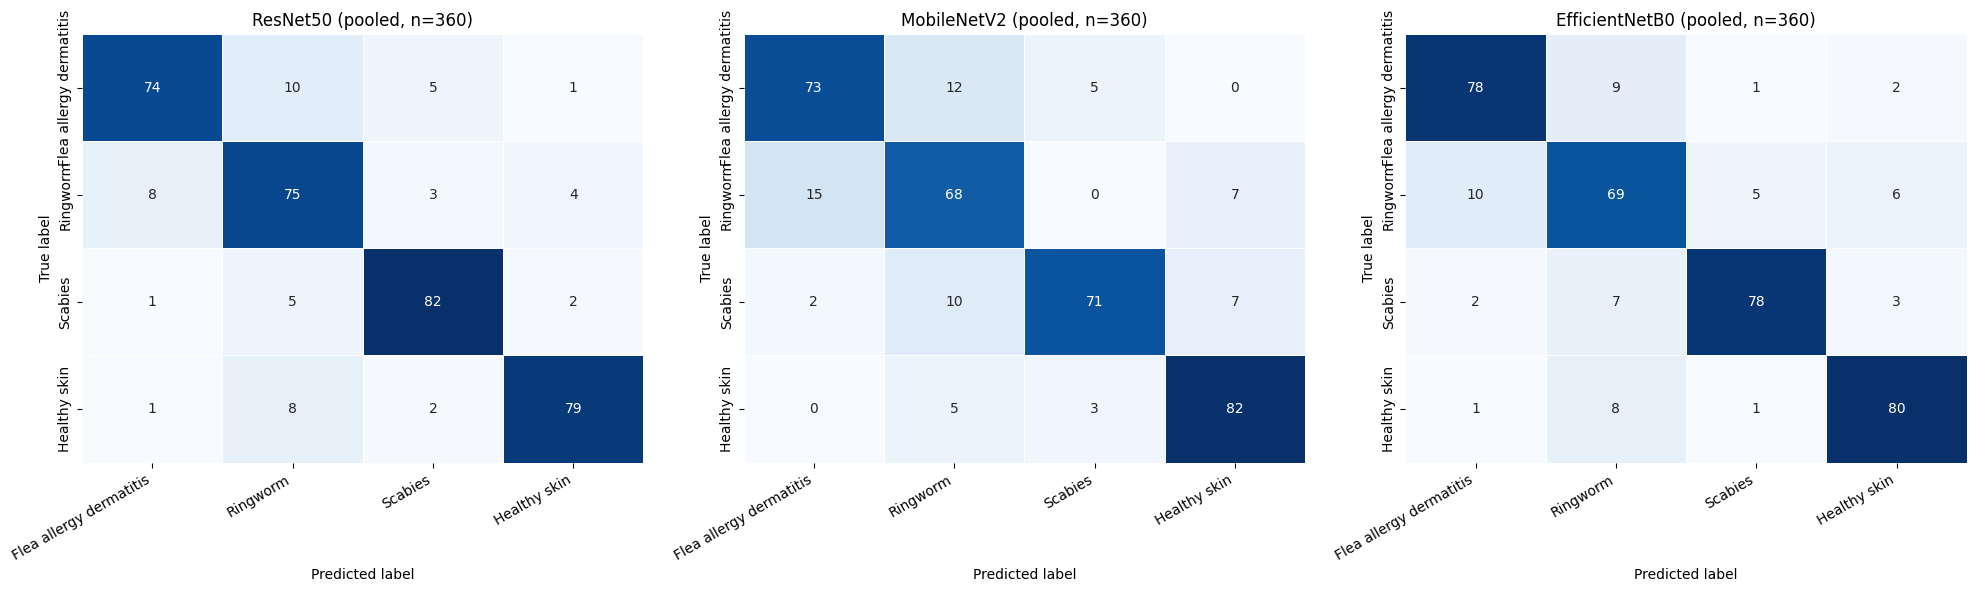

         model                                                  metric  library  by_hand  match
      ResNet50                                accuracy = correct/total 0.861111 0.861111   True
      ResNet50                         macro-F1 = mean of per-class F1 0.861818 0.861818   True
      ResNet50                 MCC (multiclass, from confusion matrix) 0.815318 0.815318   True
      ResNet50 per-fold accuracy mean == pooled accuracy (equal folds) 0.861111 0.861111   True
   MobileNetV2                                accuracy = correct/total 0.816667 0.816667   True
   MobileNetV2                         macro-F1 = mean of per-class F1 0.817051 0.817051   True
   MobileNetV2                 MCC (multiclass, from confusion matrix) 0.756264 0.756264   True
   MobileNetV2 per-fold accuracy mean == pooled accuracy (equal folds) 0.816667 0.816667   True
EfficientNetB0                                accuracy = correct/total 0.847222 0.847222   True
EfficientNetB0                         m

In [ ]:
# ============================================================
# R4 (v5): Classification performance (RQ1 / RO1)
#   - pooled over the 360 out-of-fold predictions (each image once)
#   - per fold (5 folds), summarised as mean +/- SD
#   - per-class precision / recall / F1 / support (+ specificity)
#   - confusion matrices in the fixed order FAD, Ringworm, Scabies, Healthy
#   - independent re-computation of accuracy, macro-F1 and MCC
# ============================================================
import matplotlib.pyplot as plt, seaborn as sns

# ---- pooled overall ----
cls_rows = []
for a in MODELS:
    o = overall(Y_TRUE, Y_PRED[a])
    pf = per_fold_df[per_fold_df.model == a]
    cls_rows.append(dict(model=a, n=len(Y_TRUE), correct=int(np.sum(Y_PRED[a] == Y_TRUE)),
        pooled_accuracy=o['accuracy'], pooled_macro_f1=o['macro_f1'], pooled_mcc=o['mcc'],
        fold_mean_accuracy=pf.accuracy.mean(), fold_sd_accuracy_ddof0=pf.accuracy.std(ddof=0), fold_sd_accuracy_ddof1=pf.accuracy.std(ddof=1),
        fold_mean_macro_f1=pf.macro_f1.mean(), fold_sd_macro_f1_ddof0=pf.macro_f1.std(ddof=0), fold_sd_macro_f1_ddof1=pf.macro_f1.std(ddof=1),
        fold_mean_mcc=pf.mcc.mean(), fold_sd_mcc_ddof0=pf.mcc.std(ddof=0), fold_sd_mcc_ddof1=pf.mcc.std(ddof=1)))
classification_df = pd.DataFrame(cls_rows)

# ---- per class (pooled) and per fold ----
per_class_df = pd.concat([per_class_table(Y_TRUE, Y_PRED[a]).assign(model=a) for a in MODELS])
per_class_df = per_class_df[['model', 'class', 'precision', 'recall', 'f1', 'specificity', 'support']]
pf_class = []
for a in MODELS:
    for f in range(1, N_SPLITS + 1):
        d = records[(a, f)]
        pf_class.append(per_class_table(d.y_true, d.y_pred).assign(model=a, fold=f))
per_fold_class_df = pd.concat(pf_class)[['model', 'fold', 'class', 'precision', 'recall', 'f1', 'specificity', 'support']]

# ---- confusion matrices (pooled + per fold) ----
CMS = {a: cm_display(Y_TRUE, Y_PRED[a]) for a in MODELS}
cm_rows = []
for a in MODELS:
    for f in ['pooled'] + list(range(1, N_SPLITS + 1)):
        if f == 'pooled': cm = CMS[a]
        else:
            d = records[(a, f)]; cm = cm_display(d.y_true, d.y_pred)
        for i, tn in enumerate(DISPLAY_NAMES):
            cm_rows.append(dict(model=a, fold=f, true_class=tn, **{f'pred_{pn}': int(cm[i, j]) for j, pn in enumerate(DISPLAY_NAMES)}))
cm_df = pd.DataFrame(cm_rows)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, a in zip(axes, MODELS):
    sns.heatmap(CMS[a], annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=DISPLAY_NAMES,
                yticklabels=DISPLAY_NAMES, linewidths=0.5, ax=ax)
    ax.set_title(f'{a} (pooled, n={CMS[a].sum()})'); ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout(); plt.savefig(out('confusion_matrices_pooled.png'), dpi=150, bbox_inches='tight'); plt.show()
for a in MODELS:   # one figure per model as well (manuscript-ready)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(CMS[a], annot=True, fmt='d', cmap='Blues', xticklabels=DISPLAY_NAMES,
                yticklabels=DISPLAY_NAMES, linewidths=0.5, ax=ax)
    ax.set_title(f'Confusion matrix - {a} (5 folds pooled, n={CMS[a].sum()})')
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right'); plt.tight_layout()
    plt.savefig(out(f'confusion_matrix_pooled_{a}.png'), dpi=150, bbox_inches='tight'); plt.close(fig)

# ---- independent verification ----
ver = []
for a in MODELS:
    cm = CMS[a]; o = overall(Y_TRUE, Y_PRED[a])
    acc_hand = np.trace(cm) / cm.sum()
    tp = np.diag(cm).astype(float); prec = tp / cm.sum(0); rec = tp / cm.sum(1)
    f1_hand = np.nanmean(np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0.0))
    mcc_hand = mcc_from_cm(cm)
    ver += [dict(model=a, metric='accuracy = correct/total', library=o['accuracy'], by_hand=acc_hand),
            dict(model=a, metric='macro-F1 = mean of per-class F1', library=o['macro_f1'], by_hand=f1_hand),
            dict(model=a, metric='MCC (multiclass, from confusion matrix)', library=o['mcc'], by_hand=mcc_hand),
            dict(model=a, metric='per-fold accuracy mean == pooled accuracy (equal folds)',
                 library=o['accuracy'], by_hand=per_fold_df[per_fold_df.model == a].accuracy.mean())]
ver_df = pd.DataFrame(ver); ver_df['match'] = np.isclose(ver_df.library, ver_df.by_hand, atol=1e-12)
print(ver_df.to_string(index=False)); assert ver_df.match.all(), 'metric verification failed'

pd.set_option('display.float_format', '{:.4f}'.format)
print('\nPOOLED (360) and FOLD mean +/- SD:')
print(classification_df.to_string(index=False))
print('\nPER CLASS (pooled 360):'); print(per_class_df.to_string(index=False))

classification_df.to_csv(out('classification_results.csv'), index=False)
per_fold_df.to_csv(out('per_fold_results.csv'), index=False)
per_class_df.to_csv(out('per_class_results.csv'), index=False)
per_fold_class_df.to_csv(out('per_fold_per_class_results.csv'), index=False)
cm_df.to_csv(out('confusion_matrices.csv'), index=False)
ver_df.to_csv(out('validation_metric_checks.csv'), index=False)
log_prov('Accuracy / macro-F1 / MCC per fold', 'recalculated from predictions', 'equal to CELL 6 values when MATCHES_V43')
log_prov('Pooled accuracy / macro-F1 / MCC, per-class metrics, confusion matrices (all folds)', 'recalculated from predictions')


In [ ]:
# ============================================================
# R5 (v5): Disease-versus-healthy screening (RO1)
#
# Collapse rule (applied to the existing 4-class predictions; no retraining):
#   disease  = Flea allergy dermatitis, Ringworm, Scabies   (POSITIVE class)
#   healthy  = Healthy skin                                  (NEGATIVE class)
#   TP = diseased image predicted as ANY disease (even the wrong disease)
#   FN = diseased image predicted as Healthy skin   ("sick cat called healthy")
#   TN = healthy image predicted as Healthy skin
#   FP = healthy image predicted as any disease
# Sensitivity = recall = TP/(TP+FN); specificity = TN/(TN+FP);
# precision (PPV) = TP/(TP+FP); NPV = TN/(TN+FN); F1 = 2TP/(2TP+FP+FN).
# ============================================================
scr_rows = []
for a in MODELS:
    scr_rows.append(dict(model=a, fold='pooled', **screening(Y_TRUE, Y_PRED[a])))
    for f in range(1, N_SPLITS + 1):
        d = records[(a, f)]
        scr_rows.append(dict(model=a, fold=f, **screening(d.y_true, d.y_pred)))
screening_df = pd.DataFrame(scr_rows)
# sanity: positives = 270 diseased, negatives = 90 healthy in the pooled view
for a in MODELS:
    s = screening_df[(screening_df.model == a) & (screening_df.fold == 'pooled')].iloc[0]
    assert s.TP + s.FN == int(np.sum(Y_TRUE != HEALTHY_INT)) and s.TN + s.FP == int(np.sum(Y_TRUE == HEALTHY_INT))
print(screening_df[screening_df.fold == 'pooled'].drop(columns='fold').to_string(index=False))
screening_df.to_csv(out('screening_results.csv'), index=False)
log_prov('Disease-vs-healthy screening (pooled + every fold)', 'recalculated from predictions',
         'previously only fold 1 (sensitivity/specificity)')


         model  TP  FN  TN  FP  sensitivity  recall  specificity  precision    npv     f1  accuracy  diseased_called_healthy  healthy_called_diseased
      ResNet50 263   7  79  11       0.9741  0.9741       0.8778     0.9599 0.9186 0.9669    0.9500                        7                       11
   MobileNetV2 256  14  82   8       0.9481  0.9481       0.9111     0.9697 0.8542 0.9588    0.9389                       14                        8
EfficientNetB0 259  11  80  10       0.9593  0.9593       0.8889     0.9628 0.8791 0.9610    0.9417                       11                       10


In [ ]:
# ============================================================
# R6 (v5): Pairwise McNemar tests on the POOLED 360 predictions (RQ2/RO2)
#
# Pairing: every image has exactly one out-of-fold prediction per model and
# the three models see the same images in the same folds, so the predictions
# are paired by image.
# 2x2 table convention (Model A rows, Model B columns):
#                    B correct   B incorrect
#   A correct          n00          n01
#   A incorrect        n10          n11
# Only the discordant cells n01 and n10 enter the test. H0: P(n01) = P(n10),
# i.e. equal accuracy. Test variant: same rule as CELL 9 (exact binomial if
# n01+n10 < 25, otherwise chi-square with continuity correction).
# Multiple comparisons: Holm step-down over the 3 tests; the significance
# decision uses the Holm-adjusted p-value at alpha = 0.05.
# [REFERENCE NEEDED: multiple-comparison correction] -- cite a source for
# Holm (1979) only after you have verified it yourself.
# ============================================================
PAIRS = [('ResNet50', 'MobileNetV2'), ('ResNet50', 'EfficientNetB0'), ('MobileNetV2', 'EfficientNetB0')]
mc_rows = []
for A, B_ in PAIRS:
    c = mcnemar_counts(Y_TRUE, Y_PRED[A], Y_PRED[B_])
    variant, stat, p = mcnemar_test(c['n01'], c['n10'])
    n = c['n01'] + c['n10']
    p_exact = float(binomtest(min(c['n01'], c['n10']), n, 0.5).pvalue) if n else 1.0
    p_chi_cc = float(chi2.sf((abs(c['n01'] - c['n10']) - 1) ** 2 / n, 1)) if n else 1.0
    p_chi = float(chi2.sf((c['n01'] - c['n10']) ** 2 / n, 1)) if n else 1.0
    mc_rows.append(dict(comparison=f'{A} vs {B_}', model_A=A, model_B=B_, **c,
                        correct_A=c['n00'] + c['n01'], correct_B=c['n00'] + c['n10'],
                        test=variant, statistic=stat, p_raw=p,
                        p_exact_binomial=p_exact, p_chi2_cc=p_chi_cc, p_chi2_no_cc=p_chi))
mcnemar_df = pd.DataFrame(mc_rows)
mcnemar_df['p_holm'] = holm(mcnemar_df['p_raw'])
mcnemar_df['significant_at_0.05'] = mcnemar_df['p_holm'] < ALPHA

def _interp(r):
    if r['significant_at_0.05']:
        hi, lo = (r.model_A, r.model_B) if r.n01 > r.n10 else (r.model_B, r.model_A)
        return (f'Significant difference in accuracy (Holm p {"" if r.p_holm < 1e-4 else "= "}{fmt_p(r.p_holm)}): {hi} was correct on '
                f'{max(r.n01, r.n10)} images that {lo} misclassified, versus {min(r.n01, r.n10)} the other way.')
    return (f'No statistically significant difference in accuracy (Holm p = {fmt_p(r.p_holm)}); '
            f'the models disagreed on {r.n01 + r.n10} images ({r.n01} vs {r.n10}). '
            'This does not show that the two models are equivalent.')
mcnemar_df['interpretation'] = mcnemar_df.apply(_interp, axis=1)

# ---- verification ----
try:
    from statsmodels.stats.contingency_tables import mcnemar as sm_mcnemar
    from statsmodels.stats.multitest import multipletests
    for _, r in mcnemar_df.iterrows():
        sm = sm_mcnemar([[r.n00, r.n01], [r.n10, r.n11]], exact=(r.n01 + r.n10) < 25, correction=True)
        assert np.isclose(sm.pvalue, r.p_raw), f'p mismatch for {r.comparison}'
    assert np.allclose(multipletests(mcnemar_df.p_raw, method='holm')[1], mcnemar_df.p_holm)
    print('VERIFIED: raw p-values match statsmodels.mcnemar; Holm p-values match statsmodels.multipletests.')
except ImportError:
    print('statsmodels not installed -- p-values verified only against scipy (exact/chi-square columns).')
for _, r in mcnemar_df.iterrows():   # n01/n10 recount and accuracy-difference identity
    assert r.n00 + r.n01 + r.n10 + r.n11 == len(Y_TRUE)
    assert r.correct_A - r.correct_B == r.n01 - r.n10
    assert r.correct_A == int(np.sum(Y_PRED[r.model_A] == Y_TRUE))
    alt = (r.p_exact_binomial < ALPHA, r.p_chi2_cc < ALPHA, r.p_chi2_no_cc < ALPHA)
    if len(set(alt)) > 1:
        print(f'NOTE: for {r.comparison} the RAW decision depends on the McNemar variant '
              f'(exact={r.p_exact_binomial:.4f}, chi2cc={r.p_chi2_cc:.4f}, chi2={r.p_chi2_no_cc:.4f}).')
print()
show = ['comparison', 'n00', 'n01', 'n10', 'n11', 'test', 'statistic', 'p_raw', 'p_holm', 'significant_at_0.05']
print(mcnemar_df[show].to_string(index=False, formatters={'p_raw': '{:.3g}'.format, 'p_holm': '{:.3g}'.format}))
for _, r in mcnemar_df.iterrows(): print(' -', r.comparison + ':', r.interpretation)
mcnemar_df.to_csv(out('mcnemar_results.csv'), index=False)
log_prov('Pairwise McNemar (pooled 360) + Holm', 'newly generated', 'replaces fold-1 McNemar as the RQ2 result')

# ---- Previous fold-1 exploratory analysis (reference only, NOT the RQ2 result) ----
f1_rows = []
for A, B_ in PAIRS:
    dA, dB = records[(A, 1)], records[(B_, 1)]
    c = mcnemar_counts(dA.y_true, dA.y_pred, dB.y_pred)
    variant, stat, p = mcnemar_test(c['n01'], c['n10'])
    f1_rows.append(dict(comparison=f'{A} vs {B_}', **c, test=variant, p_raw=p))
fold1_mcnemar_df = pd.DataFrame(f1_rows)
print('\nPrevious fold-1 exploratory analysis (72 images; NOT used for RQ2):')
print(fold1_mcnemar_df.to_string(index=False))
fold1_mcnemar_df.to_csv(out('previous_fold1_mcnemar_exploratory.csv'), index=False)


VERIFIED: raw p-values match statsmodels.mcnemar; Holm p-values match statsmodels.multipletests.

                   comparison  n00  n01  n10  n11                                    test  statistic  p_raw p_holm  significant_at_0.05
      ResNet50 vs MobileNetV2  276   34   18   32 chi-square, continuity-corrected (df=1)     4.3269 0.0375  0.113                False
   ResNet50 vs EfficientNetB0  284   26   21   29 chi-square, continuity-corrected (df=1)     0.3404   0.56   0.56                False
MobileNetV2 vs EfficientNetB0  275   19   30   36 chi-square, continuity-corrected (df=1)     2.0408  0.153  0.306                False
 - ResNet50 vs MobileNetV2: No statistically significant difference in accuracy (Holm p = 0.1125); the models disagreed on 52 images (34 vs 18). This does not show that the two models are equivalent.
 - ResNet50 vs EfficientNetB0: No statistically significant difference in accuracy (Holm p = 0.5596); the models disagreed on 47 images (26 vs 21). This does 

In [ ]:
# ============================================================
# R7 (v5): Bootstrap 95% confidence intervals (descriptive only)
#
# Re-implements CELL 7b EXACTLY (same seed, same B, same model order, same
# image order, same percentile method) and adds MCC computed on the SAME
# resamples. Because MCC adds no random draws, the accuracy and macro-F1
# intervals are identical to what CELL 7b produces -> this verifies CELL 7b.
#   resampling unit : individual image (360 pooled out-of-fold predictions)
#   B               : 2000 resamples
#   seed            : numpy default_rng(42), drawn sequentially over models
#                     in ARCH_CONFIG order (ResNet50, EfficientNetB0, MobileNetV2)
#   CI method       : percentile (2.5th and 97.5th percentiles)
# The CIs describe uncertainty; the paired accuracy comparison is McNemar (R6).
# ============================================================
rng = np.random.default_rng(BOOT_SEED)
boot_rows = []
for a in ARCH_CONFIG:                        # same order as CELL 7b
    yt = Y_TRUE; yp = Y_PRED[a]               # fold 1..5 concatenated, generator order (as CELL 7b)
    idx = np.arange(len(yt)); accs, f1s, mccs = [], [], []
    for _ in range(B_BOOT):
        s = rng.choice(idx, size=len(idx), replace=True)
        accs.append(np.mean(yp[s] == yt[s]))
        f1s.append(f1_score(yt[s], yp[s], average='macro'))
        mccs.append(matthews_corrcoef(yt[s], yp[s]))
    for name, pt, dist in [('accuracy', np.mean(yp == yt), accs),
                           ('macro_f1', f1_score(yt, yp, average='macro'), f1s),
                           ('mcc', matthews_corrcoef(yt, yp), mccs)]:
        lo, hi = np.percentile(dist, [2.5, 97.5])
        boot_rows.append(dict(model=a, metric=name, point=float(pt), ci_low=float(lo), ci_high=float(hi),
                              B=B_BOOT, seed=BOOT_SEED, method='percentile', unit='image'))
bootstrap_df = pd.DataFrame(boot_rows)
bootstrap_df['_o'] = bootstrap_df.model.map(MODELS.index); bootstrap_df = bootstrap_df.sort_values(['_o', 'metric']).drop(columns='_o')
print(bootstrap_df.to_string(index=False))

# ---- verify against the CELL 7b printout ----
ok = True
for a in MODELS:
    r = REF_V43['bootstrap'][a]; g = bootstrap_df.set_index(['model', 'metric'])
    got = tuple(float(x) for x in (round(g.loc[(a, 'accuracy'), 'ci_low'] * 100, 1), round(g.loc[(a, 'accuracy'), 'ci_high'] * 100, 1),
           round(g.loc[(a, 'macro_f1'), 'ci_low'], 3), round(g.loc[(a, 'macro_f1'), 'ci_high'], 3)))
    exp = (r['acc_ci'][0], r['acc_ci'][1], r['f1_ci'][0], r['f1_ci'][1])
    same = all(abs(x - y) < 1e-9 for x, y in zip(got, exp)); ok &= same
    print(f'{a:<15} acc/F1 CI now {got}  v4.3 {exp}  ->', 'MATCH' if same else 'DIFFERENT')
print('Bootstrap CIs for accuracy/macro-F1', 'VERIFIED against CELL 7b.' if ok else
      'differ from CELL 7b (expected if predictions differ from v4.3).')
bootstrap_df.to_csv(out('bootstrap_confidence_intervals.csv'), index=False)
log_prov('Bootstrap CIs accuracy & macro-F1', 'reused/verified' if ok else 'recalculated (re-run)', 'CELL 7b method')
log_prov('Bootstrap CI for MCC', 'newly generated', 'same resamples as accuracy/macro-F1')


         model   metric  point  ci_low  ci_high    B  seed     method  unit
      ResNet50 accuracy 0.8611  0.8250   0.8972 2000    42 percentile image
      ResNet50 macro_f1 0.8618  0.8265   0.8977 2000    42 percentile image
      ResNet50      mcc 0.8153  0.7674   0.8635 2000    42 percentile image
   MobileNetV2 accuracy 0.8167  0.7750   0.8556 2000    42 percentile image
   MobileNetV2 macro_f1 0.8171  0.7745   0.8560 2000    42 percentile image
   MobileNetV2      mcc 0.7563  0.7021   0.8097 2000    42 percentile image
EfficientNetB0 accuracy 0.8472  0.8111   0.8833 2000    42 percentile image
EfficientNetB0 macro_f1 0.8478  0.8102   0.8834 2000    42 percentile image
EfficientNetB0      mcc 0.7964  0.7478   0.8447 2000    42 percentile image
ResNet50        acc/F1 CI now (82.5, 89.7, 0.826, 0.898)  v4.3 (82.5, 89.7, 0.826, 0.898)  -> MATCH
MobileNetV2     acc/F1 CI now (77.5, 85.6, 0.774, 0.856)  v4.3 (77.5, 85.6, 0.774, 0.856)  -> MATCH
EfficientNetB0  acc/F1 CI now (81.1, 88.

In [ ]:
# ============================================================
# R8 (v5): Parameter counts per training phase (RO1)
#
# Phase 1: backbone frozen (base.trainable = False), only the head trains.
# Phase 2: last 30% of backbone layers unfrozen, BatchNorm layers kept frozen
#          (unfreeze_top_layers, CELL 5). This is the state of the FINAL
#          evaluated models (checkpoints are saved after Phase 2).
# Counts come from Keras' own trainable/non-trainable weight lists (the
# TF/Keras equivalent of requires_grad). BatchNorm moving mean/variance are
# always non-trainable. Total is identical in both phases; only the split moves.
# ============================================================
def weight_counts(m):
    tr = int(sum(int(np.prod(w.shape)) for w in m.trainable_weights))
    nt = int(sum(int(np.prod(w.shape)) for w in m.non_trainable_weights))
    return dict(total=int(m.count_params()), trainable=tr, non_trainable=nt)

param_rows = []
for a in MODELS:
    m, base = build_model(a)                      # identical to CELL 6
    p1 = weight_counts(m)
    m, _ = unfreeze_top_layers(m, base)           # identical to CELL 6
    p2 = weight_counts(m)
    n_layers = len(base.layers)
    del m, base; tf.keras.backend.clear_session(); gc.collect()
    # the actual saved final models (all folds) must be in the Phase-2 state
    final_states = []
    for f in range(1, N_SPLITS + 1):
        ck = next((os.path.join(d, f'{a}_fold{f}.keras') for d in [CKPT_DIR, os.path.join(V5_OUT_DIR, 'ckpts')]
                   if os.path.exists(os.path.join(d, f'{a}_fold{f}.keras'))), None)
        if ck:
            mm = tf.keras.models.load_model(ck); final_states.append(weight_counts(mm))
            del mm; tf.keras.backend.clear_session()
    for phase, c in [('Phase 1 (frozen backbone)', p1), ('Phase 2 / final model', p2)]:
        assert c['total'] == c['trainable'] + c['non_trainable'], f'{a} {phase}: total != trainable + non-trainable'
        param_rows.append(dict(model=a, phase=phase, **c, backbone_layers=n_layers))
    if final_states:
        same = all(s == p2 for s in final_states)
        print(f'{a:<15} saved final checkpoints checked: {len(final_states)}/{N_SPLITS} '
              f'-> {"all equal to Phase-2 counts" if same else "MISMATCH: " + str(final_states)}')
        assert same
    else:
        print(f'{a:<15} no checkpoints on disk -> Phase-2 counts come from the rebuilt model only')
params_df = pd.DataFrame(param_rows)
assert (params_df.groupby('model').total.nunique() == 1).all()
for a in MODELS:
    assert params_df[params_df.model == a].total.iloc[0] == REF_V43['total_params'][a], f'{a} total differs from v4.3'
print('\n' + params_df.to_string(index=False))
print('\nVERIFIED: total = trainable + non-trainable in every state; totals equal the v4.3 CELL 12 values.')
params_df.to_csv(out('parameter_counts_by_phase.csv'), index=False)
log_prov('Total parameters', 'reused/verified', 'CELL 12 value')
log_prov('Trainable / non-trainable parameters, Phase 1 and Phase 2', 'newly generated',
         'Phase-2 trainable was computed in CELL 12 but never printed; Phase 1 never computed')


      unfroze last 52/175 base layers (16 BN kept frozen)
ResNet50        saved final checkpoints checked: 5/5 -> all equal to Phase-2 counts
      unfroze last 46/154 base layers (16 BN kept frozen)
MobileNetV2     saved final checkpoints checked: 5/5 -> all equal to Phase-2 counts
      unfroze last 71/238 base layers (15 BN kept frozen)
EfficientNetB0  saved final checkpoints checked: 5/5 -> all equal to Phase-2 counts

         model                     phase    total  trainable  non_trainable  backbone_layers
      ResNet50 Phase 1 (frozen backbone) 24113284     525572       23587712              175
      ResNet50     Phase 2 / final model 24113284   17710340        6402944              175
   MobileNetV2 Phase 1 (frozen backbone)  2586948     328964        2257984              154
   MobileNetV2     Phase 2 / final model  2586948    2052804         534144              154
EfficientNetB0 Phase 1 (frozen backbone)  4378535     328964        4049571              238
EfficientNetB0 

In [ ]:
# ============================================================
# R9 (v5): FLOPs (RO1) -- SAME method as CELL 13
#   TF v1 profiler 'float_operation' on the frozen inference graph,
#   input (1, 224, 224, 3) float32, training=False. This profiler counts a
#   multiply and an add as 2 FLOPs (so FLOPs ~ 2 x multiply-accumulates).
# Ratios are computed from the UNROUNDED integers.
# ============================================================
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

FLOPS_INPUT_SPEC = (1, IMG_SIZE[0], IMG_SIZE[1], 3)
def flops_tf_profiler(model):
    @tf.function
    def forward(x): return model(x, training=False)
    concrete = forward.get_concrete_function(tf.TensorSpec(FLOPS_INPUT_SPEC, tf.float32))
    assert tuple(concrete.inputs[0].shape) == FLOPS_INPUT_SPEC
    frozen = convert_variables_to_constants_v2(concrete)
    with tf.Graph().as_default() as g:
        tf.graph_util.import_graph_def(frozen.graph.as_graph_def(), name='')
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        opts['output'] = 'none'
        fl = tf.compat.v1.profiler.profile(g, run_meta=tf.compat.v1.RunMetadata(), cmd='op', options=opts)
    return int(fl.total_float_ops)

REP_FOLD = globals().get('REP_FOLD', 1)
_ck_dir = next(d for d in [CKPT_DIR, os.path.join(V5_OUT_DIR, 'ckpts')]
               if os.path.exists(os.path.join(d, f'{MODELS[0]}_fold{REP_FOLD}.keras')))
FINAL_MODELS = {a: tf.keras.models.load_model(os.path.join(_ck_dir, f'{a}_fold{REP_FOLD}.keras')) for a in MODELS}
FLOPS = {a: flops_tf_profiler(FINAL_MODELS[a]) for a in MODELS}
print(f'Input to FLOPs graph: {FLOPS_INPUT_SPEC}, float32 (same as CELL 13)')
for a in MODELS:
    tag = 'same as v4.3' if FLOPS[a] == REF_V43['flops'][a] else f'v4.3 had {REF_V43["flops"][a]:,}'
    print(f'{a:<15} {FLOPS[a]:>15,} FLOPs = {FLOPS[a]/1e9:.4f} GFLOPs   ({tag})')
ratio_rows = []
for A, B_ in [('ResNet50', 'MobileNetV2'), ('ResNet50', 'EfficientNetB0'), ('EfficientNetB0', 'MobileNetV2')]:
    ratio_rows.append(dict(ratio=f'{A} / {B_}',
                           flops_ratio_unrounded=FLOPS[A] / FLOPS[B_],
                           flops_ratio_from_2dp_display=round(FLOPS[A] / 1e9, 2) / round(FLOPS[B_] / 1e9, 2),
                           params_ratio_unrounded=REF_V43['total_params'][A] / REF_V43['total_params'][B_]))
ratios_df = pd.DataFrame(ratio_rows)
print('\n' + ratios_df.to_string(index=False))
print('Use the *_unrounded ratios in the manuscript.')
ratios_df.to_csv(out('flops_and_parameter_ratios.csv'), index=False)
log_prov('FLOPs', 'reused/verified', 'CELL 13 method, input 1x224x224x3')
log_prov('FLOP and parameter ratios', 'recalculated from unrounded values')


Input to FLOPs graph: (1, 224, 224, 3), float32 (same as CELL 13)
ResNet50          7,752,248,216 FLOPs = 7.7522 GFLOPs   (same as v4.3)
MobileNetV2         613,383,896 FLOPs = 0.6134 GFLOPs   (same as v4.3)
EfficientNetB0      801,442,863 FLOPs = 0.8014 GFLOPs   (same as v4.3)

                       ratio  flops_ratio_unrounded  flops_ratio_from_2dp_display  params_ratio_unrounded
      ResNet50 / MobileNetV2                12.6385                       12.7049                  9.3211
   ResNet50 / EfficientNetB0                 9.6729                        9.6875                  5.5072
EfficientNetB0 / MobileNetV2                 1.3066                        1.3115                  1.6925
Use the *_unrounded ratios in the manuscript.


In [ ]:
# ============================================================
# R10 (v5): Model file size (RO1)
#
# All sizes below use ONE format: the Keras v3 '.keras' archive (the format
# CELL 6 / CELL 12 already use; Keras writes it uncompressed, ZIP_STORED).
#   (A) as_in_CELL_12 : model.save() of the loaded final checkpoint. Because the
#       checkpoint is a compiled model, the file ALSO contains the Adam optimizer
#       state (two slots per Phase-2 trainable weight). This reproduces 227.7 /
#       43.3 / 26.1.
#   (B) inference_only: same .keras format, same weights, model rebuilt from its
#       config without compile() -> no optimizer state. This is the size of the
#       model a user would deploy.
# 1 MB here = 10^6 bytes; 1 MiB = 2^20 = 1,048,576 bytes. CELL 12 divided by
# 2^20, i.e. its "MB" were MiB.
# ============================================================
size_rows = []
for a in MODELS:
    m = FINAL_MODELS[a]
    pa = f'/content/_size_{a}_A.keras'; m.save(pa); sa = os.path.getsize(pa)
    inf = tf.keras.Model.from_config(m.get_config()); inf.set_weights(m.get_weights())
    pb = f'/content/_size_{a}_B.keras'; inf.save(pb); sb = os.path.getsize(pb)
    for p in (pa, pb):
        assert p.endswith('.keras'); os.remove(p)
    weight_bytes = int(sum(int(np.prod(w.shape)) * np.dtype(str(w.dtype)).itemsize for w in m.weights))
    dtypes = sorted({str(w.dtype) for w in m.weights})
    ckpt_bytes = os.path.getsize(os.path.join(_ck_dir, f'{a}_fold{REP_FOLD}.keras'))
    for variant, b in [('A: as in CELL 12 (incl. Adam optimizer state)', sa),
                       ('B: inference-only (no optimizer state)', sb)]:
        size_rows.append(dict(model=a, variant=variant, format='.keras (Keras v3, uncompressed zip)',
                              bytes=b, MB_1e6=b / 1e6, MiB_2pow20=b / 2**20,
                              raw_weight_bytes=weight_bytes, weight_dtypes=','.join(dtypes),
                              saved_checkpoint_bytes=ckpt_bytes))
    del inf; gc.collect()
size_df = pd.DataFrame(size_rows)
print(size_df.drop(columns=['format']).to_string(index=False))
for a in MODELS:
    got = size_df[(size_df.model == a) & size_df.variant.str.startswith('A')].MiB_2pow20.iloc[0]
    print(f'{a:<15} variant A = {got:.2f} MiB vs v4.3 CELL 12 {REF_V43["size_mb"][a]} -> '
          f'{"consistent" if abs(got - REF_V43["size_mb"][a]) < 0.15 else "DIFFERENT"}')
size_df.to_csv(out('model_file_sizes.csv'), index=False)
log_prov('Model file size, variant A (CELL 12 method)', 'reused/verified')
log_prov('Model file size, variant B (inference-only, same .keras format)', 'newly generated')


         model                                       variant     bytes   MB_1e6  MiB_2pow20  raw_weight_bytes weight_dtypes  saved_checkpoint_bytes
      ResNet50 A: as in CELL 12 (incl. Adam optimizer state) 238810968 238.8110    227.7479          96453136       float32               238817517
      ResNet50        B: inference-only (no optimizer state)  97099442  97.0994     92.6012          96453136       float32               238817517
   MobileNetV2 A: as in CELL 12 (incl. Adam optimizer state)  27363163  27.3632     26.0955          10347792       float32                27368935
   MobileNetV2        B: inference-only (no optimizer state)  10924229  10.9242     10.4182          10347792       float32                27368935
EfficientNetB0 A: as in CELL 12 (incl. Adam optimizer state)  45444423  45.4444     43.3392          17514144 float32,int64                45453303
EfficientNetB0        B: inference-only (no optimizer state)  18344985  18.3450     17.4951          17514144 fl

In [ ]:
# ============================================================
# R11 (v5): Inference time (RO1)
#
# PRIMARY = the CELL 12 protocol, unchanged, applied identically to all three
# final (fold-REP_FOLD) models in this one session:
#   input      : 1 random image, 1 x 224 x 224 x 3 float32 (batch size 1)
#   mode       : eager call model(x, training=False)
#   sync       : float(tf.reduce_sum(output)) forces the GPU to finish
#   warm-up    : 5 untimed calls;  timed runs: 50;  report mean and SD (ms)
#   excluded   : model loading, preprocessing, file I/O
# SUPPLEMENTARY (clearly separate, not a replacement): the same forward pass
# compiled once with tf.function (graph mode), 20 warm-up + 200 timed runs,
# models interleaved over 3 rounds. Eager timing includes per-layer Python
# overhead, so it can rank models by layer count rather than by computation.
# ============================================================
def gpu_description():
    info = {'tf_gpus': [d.name for d in tf.config.list_physical_devices('GPU')]}
    try:
        info['gpu_name'] = tf.config.experimental.get_device_details(
            tf.config.list_physical_devices('GPU')[0]).get('device_name')
    except Exception: info['gpu_name'] = None
    try:
        info['nvidia_smi'] = subprocess.run(['nvidia-smi', '--query-gpu=name,driver_version,memory.total',
                                             '--format=csv,noheader'], capture_output=True, text=True).stdout.strip()
    except Exception: info['nvidia_smi'] = None
    try:
        info['cpu'] = next(l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
    except Exception: info['cpu'] = platform.processor()
    return info
HW = gpu_description(); print('Hardware:', HW)

def time_eager(model, n_warm=5, n_runs=50, seed=SEED):
    dummy = np.random.default_rng(seed).random((1, IMG_SIZE[0], IMG_SIZE[1], 3)).astype(np.float32)
    for _ in range(n_warm): _ = float(tf.reduce_sum(model(dummy, training=False)))
    t = []
    for _ in range(n_runs):
        t0 = time.perf_counter(); o = model(dummy, training=False); _ = float(tf.reduce_sum(o))
        t.append((time.perf_counter() - t0) * 1000)
    return np.array(t)

def time_graph(model, n_warm=20, n_runs=200, seed=SEED):
    dummy = tf.constant(np.random.default_rng(seed).random((1, IMG_SIZE[0], IMG_SIZE[1], 3)).astype(np.float32))
    fwd = tf.function(lambda x: tf.reduce_sum(model(x, training=False)))
    for _ in range(n_warm): _ = float(fwd(dummy))
    t = []
    for _ in range(n_runs):
        t0 = time.perf_counter(); _ = float(fwd(dummy)); t.append((time.perf_counter() - t0) * 1000)
    return np.array(t)

timing_rows = []
for a in MODELS:
    t = time_eager(FINAL_MODELS[a])
    timing_rows.append(dict(model=a, protocol='PRIMARY: CELL 12 protocol (eager, batch 1, 5 warm-up, 50 runs)',
                            n_runs=len(t), mean_ms=t.mean(), sd_ms=t.std(), median_ms=np.median(t),
                            v43_mean_ms=REF_V43['inference_ms'][a][0], v43_sd_ms=REF_V43['inference_ms'][a][1]))
sup = {a: [] for a in MODELS}
for rnd in range(3):
    for a in MODELS: sup[a].append(time_graph(FINAL_MODELS[a]))
for a in MODELS:
    t = np.concatenate(sup[a])
    timing_rows.append(dict(model=a, protocol='SUPPLEMENTARY: tf.function graph, batch 1, 20 warm-up, 3 x 200 runs interleaved',
                            n_runs=len(t), mean_ms=t.mean(), sd_ms=t.std(), median_ms=np.median(t)))
timing_df = pd.DataFrame(timing_rows)
timing_df['gpu'] = HW.get('nvidia_smi') or HW.get('gpu_name'); timing_df['cpu'] = HW.get('cpu')
print(timing_df.drop(columns=['gpu', 'cpu']).to_string(index=False))
print('\nAll models were timed in this session on the same hardware, input, batch size and procedure.\n'
      'v4.3 times were measured in a different Colab session; do not mix the two sets in one table.')
timing_df.to_csv(out('inference_time.csv'), index=False)
log_prov('Inference time (CELL 12 protocol)', 'newly generated (re-measured this session)', str(HW.get('nvidia_smi')))
log_prov('Inference time (graph-mode, supplementary)', 'newly generated')


Hardware: {'tf_gpus': ['/physical_device:GPU:0'], 'gpu_name': 'Tesla T4', 'nvidia_smi': 'Tesla T4, 580.82.07, 15360 MiB', 'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz'}
         model                                                                        protocol  n_runs  mean_ms   sd_ms  median_ms  v43_mean_ms  v43_sd_ms
      ResNet50                  PRIMARY: CELL 12 protocol (eager, batch 1, 5 warm-up, 50 runs)      50 270.3292 40.2705   251.5387     270.8500    51.8300
   MobileNetV2                  PRIMARY: CELL 12 protocol (eager, batch 1, 5 warm-up, 50 runs)      50 191.3199 30.9880   173.2764     171.3700    24.8200
EfficientNetB0                  PRIMARY: CELL 12 protocol (eager, batch 1, 5 warm-up, 50 runs)      50 346.6695 51.8169   323.8951     350.7100    53.4700
      ResNet50 SUPPLEMENTARY: tf.function graph, batch 1, 20 warm-up, 3 x 200 runs interleaved     600  11.7143  1.0020    11.2059          NaN        NaN
   MobileNetV2 SUPPLEMENTARY: tf.function graph, batch 1, 20 w

In [ ]:
# ============================================================
# R12 (v5): Clean results tables (RQ1/RQ2) -- no ranking, no composite score
# ============================================================
P = params_df.set_index(['model', 'phase'])
S = size_df.set_index(['model', 'variant'])
T = timing_df.set_index(['model', 'protocol'])
_prim = [p for p in timing_df.protocol.unique() if p.startswith('PRIMARY')][0]
_sup  = [p for p in timing_df.protocol.unique() if p.startswith('SUPPLEMENTARY')][0]
comp_rows = []
for a in MODELS:
    p2 = P.loc[(a, 'Phase 2 / final model')]; p1 = P.loc[(a, 'Phase 1 (frozen backbone)')]
    comp_rows.append({
        'Model': a,
        'Total Parameters': int(p2.total),
        'Trainable Parameters (Phase 2, final)': int(p2.trainable),
        'Non-trainable Parameters (Phase 2, final)': int(p2.non_trainable),
        'Trainable Parameters (Phase 1)': int(p1.trainable),
        'Non-trainable Parameters (Phase 1)': int(p1.non_trainable),
        'FLOPs': FLOPS[a], 'GFLOPs': FLOPS[a] / 1e9,
        'Model Size MiB (A: CELL 12, incl. optimizer)': S.loc[(a, 'A: as in CELL 12 (incl. Adam optimizer state)')].MiB_2pow20,
        'Model Size MiB (B: inference-only)': S.loc[(a, 'B: inference-only (no optimizer state)')].MiB_2pow20,
        'Inference ms mean (primary)': T.loc[(a, _prim)].mean_ms, 'Inference ms SD (primary)': T.loc[(a, _prim)].sd_ms,
        'Inference ms mean (supplementary graph)': T.loc[(a, _sup)].mean_ms,
    })
computational_df = pd.DataFrame(comp_rows)
computational_df.to_csv(out('computational_characteristics.csv'), index=False)

BOOT_IDX = bootstrap_df.set_index(['model', 'metric'])
perf_rows = []
for a in MODELS:
    c = classification_df.set_index('model').loc[a]
    perf_rows.append({'Model': a,
        'Accuracy (pooled)': c.pooled_accuracy, 'Accuracy 95% CI': (BOOT_IDX.loc[(a, 'accuracy')].ci_low, BOOT_IDX.loc[(a, 'accuracy')].ci_high),
        'Macro-F1 (pooled)': c.pooled_macro_f1, 'Macro-F1 95% CI': (BOOT_IDX.loc[(a, 'macro_f1')].ci_low, BOOT_IDX.loc[(a, 'macro_f1')].ci_high),
        'MCC (pooled)': c.pooled_mcc, 'MCC 95% CI': (BOOT_IDX.loc[(a, 'mcc')].ci_low, BOOT_IDX.loc[(a, 'mcc')].ci_high),
        'Accuracy fold mean +/- SD': (c.fold_mean_accuracy, c.fold_sd_accuracy_ddof0),
        'Macro-F1 fold mean +/- SD': (c.fold_mean_macro_f1, c.fold_sd_macro_f1_ddof0),
        'MCC fold mean +/- SD': (c.fold_mean_mcc, c.fold_sd_mcc_ddof0)})
performance_df = pd.DataFrame(perf_rows)
stats_table = mcnemar_df[['comparison', 'n01', 'n10', 'test', 'statistic', 'p_raw', 'p_holm', 'significant_at_0.05']].rename(
    columns={'p_raw': 'Raw p-value', 'p_holm': 'Holm-adjusted p-value', 'significant_at_0.05': 'Significant at alpha=.05?'})
performance_df.to_csv(out('classification_performance_table.csv'), index=False)
stats_table.to_csv(out('statistical_results_table.csv'), index=False)
print('Tables written: computational_characteristics.csv, classification_performance_table.csv, statistical_results_table.csv')


Tables written: computational_characteristics.csv, classification_performance_table.csv, statistical_results_table.csv


# FINAL MANUSCRIPT RESULTS

The next cell prints the exact values for Chapters 4 and 5, organised as **A. Classification Performance**, **B. Computational Characteristics**, **C. Statistical Comparisons**, **D. Strengths and Weaknesses Evidence**. It never declares an overall winner.


In [ ]:
# ============================================================
# FINAL MANUSCRIPT RESULTS (v5)
# Exact values to transfer into Chapters 4 and 5. Every number below is read
# from the dataframes computed above (nothing is typed in by hand).
# ============================================================
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
def _f(x, d=4): return f'{x:.{d}f}'
def _ci(t, d=4): return f'[{t[0]:.{d}f}, {t[1]:.{d}f}]'

print('#' * 100); print('# FINAL MANUSCRIPT RESULTS'); print('#' * 100)
print(f'Prediction source: {PRED_SOURCE}')
print(f'Reproduces original v4.3 run: {MATCHES_V43}')

# ---------------- A ----------------
print('\n## A. Classification Performance (n = 360 pooled out-of-fold predictions; 5 folds x 72)')
print(f'{"Model":<16}{"Accuracy":>10}{"95% CI":>20}{"Macro-F1":>10}{"95% CI":>20}{"MCC":>8}{"95% CI":>20}   fold mean +/- SD (acc | F1 | MCC)')
for _, r in performance_df.iterrows():
    print(f'{r.Model:<16}{_f(r["Accuracy (pooled)"]):>10}{_ci(r["Accuracy 95% CI"]):>20}{_f(r["Macro-F1 (pooled)"]):>10}'
          f'{_ci(r["Macro-F1 95% CI"]):>20}{_f(r["MCC (pooled)"]):>8}{_ci(r["MCC 95% CI"]):>20}   '
          f'{_f(r["Accuracy fold mean +/- SD"][0])}+/-{_f(r["Accuracy fold mean +/- SD"][1])} | '
          f'{_f(r["Macro-F1 fold mean +/- SD"][0])}+/-{_f(r["Macro-F1 fold mean +/- SD"][1])} | '
          f'{_f(r["MCC fold mean +/- SD"][0])}+/-{_f(r["MCC fold mean +/- SD"][1])}')
print('SD = population SD over the 5 folds (ddof=0, as in CELL 7); sample SD (ddof=1) is in classification_results.csv.')
print('\nPer-fold values:'); print(per_fold_df.pivot(index='fold', columns='model')[['accuracy', 'macro_f1', 'mcc']].round(4).to_string())
print('\nPer-class (pooled):')
print(per_class_df.pivot(index='class', columns='model')[['precision', 'recall', 'f1', 'specificity', 'support']]
      .reindex(DISPLAY_NAMES).round(4).to_string())
print('\nConfusion matrices (pooled; rows = true, cols = predicted; order:', ', '.join(DISPLAY_NAMES) + ')')
for a in MODELS: print(f'{a}:\n{CMS[a]}')
print('\nDisease-vs-healthy screening (pooled; disease = positive):')
print(screening_df[screening_df.fold == 'pooled'][['model', 'TP', 'FN', 'TN', 'FP', 'sensitivity', 'specificity',
      'precision', 'recall', 'npv', 'f1', 'accuracy']].round(4).to_string(index=False))

# ---------------- B ----------------
print('\n## B. Computational Characteristics')
print(computational_df.round(4).to_string(index=False))
print('FLOP ratios (unrounded):'); print(ratios_df.round(4).to_string(index=False))

# ---------------- C ----------------
print('\n## C. Statistical Comparisons (McNemar, pooled 360, Holm-adjusted, alpha = 0.05)')
print(stats_table.to_string(index=False, formatters={'Raw p-value': '{:.3g}'.format, 'Holm-adjusted p-value': '{:.3g}'.format}))
for _, r in mcnemar_df.iterrows(): print(' -', r.comparison + ':', r.interpretation)

# ---------------- D ----------------
print('\n## D. Strengths and Weaknesses Evidence (RQ3)')
print('Each item is RELATIVE to the other two architectures. No overall winner is declared and no '
      'composite score is computed. Accuracy differences carry their McNemar result; other metrics carry CI overlap.')
MC = mcnemar_df.set_index(['model_A', 'model_B'])
def acc_sig(a, b):
    r = MC.loc[(a, b)] if (a, b) in MC.index else MC.loc[(b, a)]
    return f'Holm p {"" if r.p_holm < 1e-4 else "= "}{fmt_p(r.p_holm)}, {"significant" if r["significant_at_0.05"] else "not significant"}'
def position(vals, a, higher_better):
    v = vals[a]; others = [vals[b] for b in MODELS if b != a]
    if all(np.isclose(v, o) for o in others): return 'tied across all three'
    better = all((v > o if higher_better else v < o) or np.isclose(v, o) for o in others)
    worse  = all((v < o if higher_better else v > o) or np.isclose(v, o) for o in others)
    tie = any(np.isclose(v, o) for o in others)
    if better: return 'best (tied)' if tie else 'best'
    if worse:  return 'worst (tied)' if tie else 'worst'
    return 'middle'
def ci_overlap(metric, a):
    me = BOOT_IDX.loc[(a, metric)]; res = []
    for b in MODELS:
        if b == a: continue
        o = BOOT_IDX.loc[(b, metric)]
        res.append(f'{b}: {"overlapping" if (me.ci_low <= o.ci_high and o.ci_low <= me.ci_high) else "non-overlapping"} CIs')
    return '; '.join(res)

CL = classification_df.set_index('model'); SC = screening_df[screening_df.fold == 'pooled'].set_index('model')
PCF = per_class_df.pivot(index='class', columns='model', values='f1').reindex(DISPLAY_NAMES)
PCR = per_class_df.pivot(index='class', columns='model', values='recall').reindex(DISPLAY_NAMES)
CP = computational_df.set_index('Model')
evidence = []
def add(a, kind, text): evidence.append(dict(model=a, kind=kind, evidence=text))
for a in MODELS:
    # --- classification ---
    for key, lab, metric in [('pooled_accuracy', 'Accuracy', 'accuracy'), ('pooled_macro_f1', 'Macro-F1', 'macro_f1'), ('pooled_mcc', 'MCC', 'mcc')]:
        vals = CL[key].to_dict(); pos = position(vals, a, True)
        extra = ('; vs ' + ', '.join(f'{b} ({acc_sig(a, b)})' for b in MODELS if b != a)) if metric == 'accuracy' else '; ' + ci_overlap(metric, a)
        kind = 'classification strength' if pos.startswith('best') else 'classification weakness' if pos.startswith('worst') else 'classification (intermediate)'
        add(a, kind, f'{lab} {vals[a]:.4f} = {pos}{"" if pos.startswith("tied") else " of the three"}{extra}')
    sd = CL['fold_sd_accuracy_ddof0'].to_dict(); pos = position(sd, a, False)
    add(a, 'classification strength' if pos.startswith('best') else 'classification weakness' if pos.startswith('worst') else 'classification (intermediate)',
        f'Fold-to-fold accuracy SD {sd[a]:.4f} = {pos} (lower = more consistent across folds)')
    for cls in DISPLAY_NAMES:
        pos = position(PCF.loc[cls].to_dict(), a, True)
        if pos.startswith('best') or pos.startswith('worst'):
            add(a, 'classification strength' if pos.startswith('best') else 'classification weakness',
                f'{cls}: F1 {PCF.loc[cls, a]:.4f} = {pos} of the three (recall {PCR.loc[cls, a]:.4f})')
    own = PCF[a]
    add(a, 'classification (own profile)', f'Easiest class: {own.idxmax()} (F1 {own.max():.4f}); hardest class: {own.idxmin()} (F1 {own.min():.4f})')
    fn = SC['FN'].to_dict(); pos = position(fn, a, False)
    add(a, 'classification strength' if pos.startswith('best') else 'classification weakness' if pos.startswith('worst') else 'classification (intermediate)',
        f'Screening: {fn[a]} of {int(SC.loc[a, "TP"] + SC.loc[a, "FN"])} diseased images predicted healthy (sensitivity {SC.loc[a, "sensitivity"]:.4f}) = {pos}')
    fp = SC['FP'].to_dict(); pos = position(fp, a, False)
    add(a, 'classification strength' if pos.startswith('best') else 'classification weakness' if pos.startswith('worst') else 'classification (intermediate)',
        f'Screening: {fp[a]} of {int(SC.loc[a, "TN"] + SC.loc[a, "FP"])} healthy images predicted diseased (specificity {SC.loc[a, "specificity"]:.4f}) = {pos}')
    # --- computational ---
    for col, lab in [('Total Parameters', 'Total parameters'), ('FLOPs', 'FLOPs'),
                     ('Model Size MiB (B: inference-only)', 'Model size, inference-only (MiB)'),
                     ('Model Size MiB (A: CELL 12, incl. optimizer)', 'Model size, CELL 12 method (MiB)'),
                     ('Inference ms mean (primary)', 'Inference time, primary protocol (ms)'),
                     ('Inference ms mean (supplementary graph)', 'Inference time, graph mode (ms)')]:
        vals = CP[col].to_dict(); pos = position(vals, a, False)
        kind = 'computational strength' if pos.startswith('best') else 'computational weakness' if pos.startswith('worst') else 'computational (intermediate)'
        add(a, kind, f'{lab}: {(f"{vals[a]:,.0f}" if col in ("Total Parameters", "FLOPs") else f"{vals[a]:,.2f}")} = {"lowest" if pos.startswith("best") else "highest" if pos.startswith("worst") else "middle"} of the three')
evidence_df = pd.DataFrame(evidence)
for a in MODELS:
    print(f'\n### {a}')
    for kind in ['classification strength', 'classification weakness', 'classification (intermediate)', 'classification (own profile)',
                 'computational strength', 'computational weakness', 'computational (intermediate)']:
        items = evidence_df[(evidence_df.model == a) & (evidence_df.kind == kind)].evidence.tolist()
        if items:
            print(f'  {kind}:')
            for it in items: print('    -', it)
evidence_df.to_csv(out('strengths_weaknesses_evidence.csv'), index=False)
log_prov('Strengths/weaknesses evidence (RQ3)', 'recalculated from results', 'relative positions only; no winner')


####################################################################################################
# FINAL MANUSCRIPT RESULTS
####################################################################################################
Prediction source: A: CELL 6 of this session (v5 records with file paths + probabilities)
Reproduces original v4.3 run: True

## A. Classification Performance (n = 360 pooled out-of-fold predictions; 5 folds x 72)
Model             Accuracy              95% CI  Macro-F1              95% CI     MCC              95% CI   fold mean +/- SD (acc | F1 | MCC)
ResNet50            0.8611    [0.8250, 0.8972]    0.8618    [0.8265, 0.8977]  0.8153    [0.7674, 0.8635]   0.8611+/-0.0412 | 0.8579+/-0.0439 | 0.8202+/-0.0532
MobileNetV2         0.8167    [0.7750, 0.8556]    0.8171    [0.7745, 0.8560]  0.7563    [0.7021, 0.8097]   0.8167+/-0.0508 | 0.8149+/-0.0517 | 0.7606+/-0.0672
EfficientNetB0      0.8472    [0.8111, 0.8833]    0.8478    [0.8102, 0.8834]  0.7964    [0.7478, 0

## Reproducibility, provenance and manuscript consistency check

Edit `MANUSCRIPT_VALUES` in the next cell so it holds the numbers currently printed in the manuscript, then run it. Every row marked **MUST UPDATE** is a manuscript value that differs from this notebook.


In [ ]:
# ============================================================
# R14 (v5): Reproducibility summary, provenance, manuscript consistency check,
# export. Only information actually read from this environment is reported.
# ============================================================
import sklearn, scipy, matplotlib
try:
    import statsmodels; _sm = statsmodels.__version__
except ImportError: _sm = 'not installed'
bi = tf.sysconfig.get_build_info()
repro = {
    'python': sys.version.split()[0], 'tensorflow': tf.__version__, 'keras': tf.keras.__version__ if hasattr(tf.keras, '__version__') else None,
    'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__,
    'statsmodels': _sm, 'matplotlib': matplotlib.__version__,
    'cuda_build': bi.get('cuda_version'), 'cudnn_build': bi.get('cudnn_version'),
    'gpu': HW.get('nvidia_smi') or HW.get('gpu_name'), 'cpu': HW.get('cpu'),
    'input_image_size': f'{IMG_SIZE[0]}x{IMG_SIZE[1]}x3 (letterboxed {SQUARE_SIZE}px square, then resized)',
    'batch_size_training_and_evaluation': BATCH_SIZE, 'batch_size_inference_timing': 1,
    'random_seed': SEED, 'op_determinism': 'tf.config.experimental.enable_op_determinism() (CELL 1)',
    'folds': N_SPLITS, 'fold_scheme': 'StratifiedKFold by image, shuffle=True, random_state=42; inner 15% validation for early stopping',
    'test_set_size': f'{len(Y_TRUE)} pooled out-of-fold predictions ({len(Y_TRUE)//N_SPLITS} per fold)',
    'bootstrap_iterations': B_BOOT, 'bootstrap_seed': BOOT_SEED, 'bootstrap_ci_method': 'percentile, image-level resampling',
    'significance_level': ALPHA, 'mcnemar_variant': MCNEMAR_RULE, 'multiple_comparison_correction': CORRECTION,
    'prediction_source': PRED_SOURCE, 'reproduces_v43_run': MATCHES_V43,
}
print('REPRODUCIBILITY SUMMARY'); [print(f'  {k:<36}: {v}') for k, v in repro.items()]
json.dump(repro, open(out('reproducibility_summary.json'), 'w'), indent=2, default=str)

log_prov('Phase-1/2 training curves, Grad-CAM, fold-1 confusion matrices', 'reused (v4.3 outputs kept in CELLs 8-11)')
prov_df = pd.DataFrame(PROVENANCE); print('\nPROVENANCE'); print(prov_df.to_string(index=False))
prov_df.to_csv(out('provenance.csv'), index=False)

# ---------------- manuscript consistency check ----------------
# EDIT these to the values currently printed in the manuscript before running.
# Pre-filled with the values used in the post-defense manuscript draft.
MANUSCRIPT_VALUES = {
    ('Table 4.1', 'ResNet50 accuracy mean %'): 86.11, ('Table 4.1', 'EfficientNetB0 accuracy mean %'): 84.72, ('Table 4.1', 'MobileNetV2 accuracy mean %'): 81.67,
    ('Table 4.1', 'ResNet50 accuracy SD %'): 4.12, ('Table 4.1', 'EfficientNetB0 accuracy SD %'): 3.83, ('Table 4.1', 'MobileNetV2 accuracy SD %'): 5.08,
    ('Table 4.1', 'ResNet50 MCC mean'): 0.820, ('Table 4.1', 'EfficientNetB0 MCC mean'): 0.801, ('Table 4.1', 'MobileNetV2 MCC mean'): 0.761,
    ('Table 4.1', 'ResNet50 macro-F1 mean'): 0.858, ('Table 4.1', 'EfficientNetB0 macro-F1 mean'): 0.846, ('Table 4.1', 'MobileNetV2 macro-F1 mean'): 0.815,
    ('Sec 4.3', 'ResNet50 accuracy CI low %'): 82.5, ('Sec 4.3', 'ResNet50 accuracy CI high %'): 89.7,
    ('Sec 4.3', 'EfficientNetB0 accuracy CI low %'): 81.1, ('Sec 4.3', 'EfficientNetB0 accuracy CI high %'): 88.3,
    ('Sec 4.3', 'MobileNetV2 accuracy CI low %'): 77.5, ('Sec 4.3', 'MobileNetV2 accuracy CI high %'): 85.6,
    ('Table 4.3', 'ResNet50 GFLOPs'): 7.75, ('Table 4.3', 'EfficientNetB0 GFLOPs'): 0.80, ('Table 4.3', 'MobileNetV2 GFLOPs'): 0.61,
    ('Table 4.3', 'ResNet50 size MB'): 227.7, ('Table 4.3', 'EfficientNetB0 size MB'): 43.3, ('Table 4.3', 'MobileNetV2 size MB'): 26.1,
    ('Table 4.3', 'ResNet50 inference ms'): 270.9, ('Table 4.3', 'EfficientNetB0 inference ms'): 350.7, ('Table 4.3', 'MobileNetV2 inference ms'): 171.4,
    ('Sec 4.6', 'FLOPs ratio ResNet50/MobileNetV2'): 12.6, ('Sec 4.6', 'FLOPs ratio ResNet50/EfficientNetB0'): 9.7,
    ('Sec 4.6', 'params ratio ResNet50/EfficientNetB0'): 5.5, ('Sec 4.6', 'params ratio ResNet50/MobileNetV2'): 9.3,
}
CLs = classification_df.set_index('model'); Bt = bootstrap_df.set_index(['model', 'metric']); Tm = timing_df.set_index(['model', 'protocol'])
Rt = ratios_df.set_index('ratio')
NEW = {}
for a in MODELS:
    NEW[('Table 4.1', f'{a} accuracy mean %')] = (round(CLs.loc[a].fold_mean_accuracy * 100, 2), 2)
    NEW[('Table 4.1', f'{a} accuracy SD %')] = (round(CLs.loc[a].fold_sd_accuracy_ddof0 * 100, 2), 2)
    NEW[('Table 4.1', f'{a} MCC mean')] = (round(CLs.loc[a].fold_mean_mcc, 3), 3)
    NEW[('Table 4.1', f'{a} macro-F1 mean')] = (round(CLs.loc[a].fold_mean_macro_f1, 3), 3)
    NEW[('Sec 4.3', f'{a} accuracy CI low %')] = (round(Bt.loc[(a, 'accuracy')].ci_low * 100, 1), 1)
    NEW[('Sec 4.3', f'{a} accuracy CI high %')] = (round(Bt.loc[(a, 'accuracy')].ci_high * 100, 1), 1)
    NEW[('Table 4.3', f'{a} GFLOPs')] = (round(FLOPS[a] / 1e9, 2), 2)
    NEW[('Table 4.3', f'{a} size MB')] = (round(size_df[(size_df.model == a) & size_df.variant.str.startswith('A')].MiB_2pow20.iloc[0], 1), 1)
    NEW[('Table 4.3', f'{a} inference ms')] = (round(Tm.loc[(a, _prim)].mean_ms, 1), 1)
NEW[('Sec 4.6', 'FLOPs ratio ResNet50/MobileNetV2')] = (round(Rt.loc['ResNet50 / MobileNetV2'].flops_ratio_unrounded, 1), 1)
NEW[('Sec 4.6', 'FLOPs ratio ResNet50/EfficientNetB0')] = (round(Rt.loc['ResNet50 / EfficientNetB0'].flops_ratio_unrounded, 1), 1)
NEW[('Sec 4.6', 'params ratio ResNet50/EfficientNetB0')] = (round(Rt.loc['ResNet50 / EfficientNetB0'].params_ratio_unrounded, 1), 1)
NEW[('Sec 4.6', 'params ratio ResNet50/MobileNetV2')] = (round(Rt.loc['ResNet50 / MobileNetV2'].params_ratio_unrounded, 1), 1)
cons = []
for k, old in MANUSCRIPT_VALUES.items():
    new, _ = NEW.get(k, (None, None))
    cons.append(dict(section=k[0], item=k[1], manuscript=old, notebook=new,
                     status='unchanged' if new is not None and abs(new - old) < 1e-9 else 'MUST UPDATE'))
cons_df = pd.DataFrame(cons)
print('\nMANUSCRIPT CONSISTENCY CHECK'); print(cons_df.to_string(index=False))
print('\nNew items with no manuscript value yet (must be ADDED): pooled per-class metrics, pooled confusion matrices, '
      'pooled screening, Phase-1/2 trainable counts, inference-only model size, pooled McNemar + Holm, MCC CIs.')
print('Claims to re-check: any "best balance", "best model", "statistically superior/significantly better", and any '
      'statement that MobileNetV2 significance "was not determined" -- now determined in R6.')
cons_df.to_csv(out('manuscript_consistency_check.csv'), index=False)

# ---------------- export ----------------
import zipfile
zp = '/content/cat_skin_results_v5.zip'
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(V5_OUT_DIR)):
        fp = os.path.join(V5_OUT_DIR, fn)
        if os.path.isfile(fp): z.write(fp, fn)
print(f'\nAll v5 outputs are in {V5_OUT_DIR} and zipped to {zp}.')
try:
    from google.colab import files; files.download(zp)
except Exception: pass


REPRODUCIBILITY SUMMARY
  python                              : 3.13.15
  tensorflow                          : 2.21.0
  keras                               : 3.13.2
  numpy                               : 2.1.3
  pandas                              : 2.2.3
  scikit-learn                        : 1.6.1
  scipy                               : 1.16.3
  statsmodels                         : 0.15.0
  matplotlib                          : 3.10.0
  cuda_build                          : 12.5.1
  cudnn_build                         : 9
  gpu                                 : Tesla T4, 580.82.07, 15360 MiB
  cpu                                 : Intel(R) Xeon(R) CPU @ 2.00GHz
  input_image_size                    : 224x224x3 (letterboxed 384px square, then resized)
  batch_size_training_and_evaluation  : 32
  batch_size_inference_timing         : 1
  random_seed                         : 42
  op_determinism                      : tf.config.experimental.enable_op_determinism() (CELL 1)
  folds  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 16: Zip all results and download to your laptop
# ============================================================
import zipfile
from google.colab import files

ZIP_NAME = 'cat_skin_results.zip'

with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_DEFLATED) as z:
    for fn in os.listdir('.'):
        if fn.endswith(('.json', '.csv', '.png')):
            z.write(fn)
            print('  added:', fn)

print(f'\nZipped -> {ZIP_NAME}')
files.download(ZIP_NAME)

  added: gradcam_MobileNetV2.png
  added: efficiency_results.json
  added: eval_results_repfold.json
  added: gradcam_ResNet50.png
  added: training_curves_MobileNetV2.png
  added: cv_summary.json
  added: summary_table.csv
  added: training_curves_ResNet50.png
  added: cv_metrics_per_fold.json
  added: gradcam_EfficientNetB0.png
  added: dedup_removed.csv
  added: confusion_matrix_EfficientNetB0.png
  added: confusion_matrix_MobileNetV2.png
  added: training_curves_EfficientNetB0.png
  added: confusion_matrix_ResNet50.png

Zipped -> cat_skin_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 18: Export ALL 3 models (best fold of each) for the Streamlit DEMO
# v5: deployment convenience only. Picking each model's highest-accuracy
#     fold is NOT a model-selection result and is NOT used in the
#     manuscript (it selects a fold per architecture, never a winner
#     between architectures, and its fold accuracy is optimistic).
# ============================================================
import zipfile
from google.colab import files

ZIP_NAME = 'all_models_streamlit.zip'
with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_STORED) as z:
    for arch in ARCH_CONFIG:
        accs = cv_metrics[arch]['accuracy']
        best_fold = int(np.argmax(accs)) + 1
        src = os.path.join(CKPT_DIR, f'{arch}_fold{best_fold}.keras')
        info = {
            'arch': arch,
            'fold': best_fold,
            'fold_accuracy': accs[best_fold - 1],
            'class_names': CLASS_NAMES,
            'img_size': list(IMG_SIZE),
            'square_size': SQUARE_SIZE,
            'pad_fill': list(PAD_FILL),
            'tf_version': tf.__version__,
        }
        z.write(src, f'models/{arch}/model.keras')
        z.writestr(f'models/{arch}/model_info.json', json.dumps(info, indent=2))
        size = os.path.getsize(src) / 1024**2
        print(f'{arch:<16} fold {best_fold}  acc={accs[best_fold-1]:.4f}  {size:.0f} MB')

print('TensorFlow version:', tf.__version__)
files.download(ZIP_NAME)

ResNet50         fold 3  acc=0.9306  228 MB
EfficientNetB0   fold 3  acc=0.9167  43 MB
MobileNetV2      fold 3  acc=0.9028  26 MB
TensorFlow version: 2.21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitations that CANNOT be fixed in code (state these in Chapter 5)

The pipeline fixes remove the *code-level* problems, but these threats to
validity are inherent to the data and design and must be disclosed:

1. **Same-cat (subject) leakage.** The public images carry no cat IDs, so a
   true subject-wise split is impossible. Multiple photos of the *same cat*
   may fall in different folds, letting a model recognise the individual
   rather than the disease. `CELL 6` splits by image and prints a warning;
   fill `GROUP_COL` if you ever obtain cat IDs.

2. **Label validity.** Labels came from public repositories and were
   relabeled by the researchers, not a veterinary dermatologist. "Cat
   scabies" images online are frequently mislabeled, and flea allergy
   dermatitis vs flea infestation is often conflated. No inter-rater
   agreement was measured. For three visually similar disease classes this caps how
   meaningful any accuracy figure can be.

3. **No external / independent test set.** All evaluation is internal CV on
   one pooled dataset from the same few sources. This shows "works on data
   like this", not "works" in a clinic with different cameras, lighting,
   breeds, and coat colours.

4. **Coat colour / breed confound.** Redness and scaling are harder to see
   on dark or long-haired cats. If the dataset skews to light short-haired
   cats — or if one class happens to contain darker cats — coat can become a
   shortcut the model exploits.

5. **Background / shortcut learning is a *check*, not a fix.** Grad-CAM
   (`CELL 10`) exists to reveal whether predictions rest on the lesion or on
   background / fur / watermarks. You must actually inspect the maps; if they
   land off-lesion, high accuracy is not trustworthy regardless of the split.

6. **Small sample size.** After dedup, each validation fold holds only a few
   dozen images. Point estimates are noisy; rely on the bootstrap CIs in
   `CELL 7b`, and treat overlapping CIs as "no detectable difference."


---
## Additional methodological notes (v5)

7. **McNemar on pooled cross-validation predictions.** The test treats the 360 images as independent paired trials. Each prediction comes from a model trained on a different (overlapping) training set, so this variability is not fully captured. Report the test as a comparison of the three training procedures on this dataset, not of single fixed models.
8. **Pooled vs fold-mean metrics.** With equal folds (72 images), pooled accuracy equals the mean fold accuracy. Pooled macro-F1 and MCC are **not** equal to their fold means. State which one each table uses.
9. **Fold SD convention.** CELL 7 uses the population SD (ddof = 0). The sample SD (ddof = 1) is larger and is saved in `classification_results.csv`. Name the convention in the manuscript.
10. **Representative fold was a tie.** Folds 1, 2 and 4 had the same three-model mean accuracy (82.87%); `argmin` picked fold 1. Fold-1 visuals (CELL 8, 10, 11) remain illustrative only.
11. **Model file size.** The v4.3 sizes (CELL 12) include the Adam optimizer state stored in the compiled checkpoint. The inference-only size (R10, variant B, same `.keras` format) is the deployable footprint. The inflation is not a constant factor, so the ratios between models differ slightly between A and B.
12. **Inference time is environment-specific.** It was measured with eager single-image calls on a shared Colab GPU. Compare the three models only within one session. The graph-mode supplement shows how much of the eager time is framework overhead.
